# Regression Methods — WPPSI-III IQ from Neonatal ECG/HRV

Template for regressing WPPSI-III IQ scores (QIT Full-Scale, QIV Verbal, QIP Performance, …) from neonatal linear + nonlinear HRV features (AuBE cohort, ~189 children, M0 recordings only).

Set ``TARGET_COLUMN`` below to the IQ you want to predict. To compare all IQs at once, use ``model_evaluation.py`` at the project root.

This notebook has been tested in Google Colab and VSCode. It is designed to use the `.env` file in this directory to locate the data files. Make sure to set it up by following the `.env.example` file.

**Research only — not a diagnostic tool.** Health data lives in `data/` and must **never** be committed or shared with AI tools.

See `Group A/dataset.md` for the full data dictionary and merge rules.

### Load data & Initialization

#### imports

In [126]:
# --------------------------------------------------------------
# 1. Imports
# --------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error,
)

# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

# Pipeline & joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import GridSearchCV, KFold, RepeatedKFold, RandomizedSearchCV 
import joblib

# Plotting style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

#### Google colab setup from vscode using colabsync

make sure to connect the colab sync

In [127]:


#loading .env file for notebooks, it looks for .env file in the current working directory
import os
os.chdir("/content")
print("Current working directory: ", os.getcwd())
#list all files in the current working directory
print("Files in current working directory: ", os.listdir(os.getcwd()))

#change the current working directory to the directory of the notebook
os.chdir("/content/international-project/FSIQ-from-ECG/GroupA/Mateo")

print("Current working directory: ", os.getcwd())
print("Files in current working directory: ", os.listdir(os.getcwd()))

%load_ext dotenv
%reload_ext dotenv
%dotenv

#reset environment variables to avoid conflicts
os.environ.pop("DATA_FILE", None)
%dotenv
#create folder for models if it doesn't exist
models_path = os.getenv("MODELS_PATH")
if not os.path.exists(models_path):
    os.makedirs(models_path)
    print(f"Created models directory: {models_path}")

Current working directory:  /content
Files in current working directory:  ['.config', 'international-project', 'sample_data']
Current working directory:  /content/international-project/FSIQ-from-ECG/GroupA/Mateo
Files in current working directory:  ['.env.exemple', '.env', 'plots', 'models', 'readme.md', 'method3.ipynb']
The dotenv extension is already loaded. To reload it, use:
  %reload_ext dotenv


#### loading data from .env file

In [128]:
data_file = os.getenv("DATA_FILE")
non_linearity_file = os.getenv("NON_LINEARITY_FILE")

def load_data(file_path):
    try:
        print(f"Loading data from {file_path}...")
        df = pd.read_csv(file_path, sep="\t", encoding="utf-8-sig", header=None) #change the delimiter to your needs.
        df = df.replace({ #fixing accents, the original file has some encoding issues, so we replace the incorrect characters with the correct ones, we cannot recover automatically
                    "Num�ro": "Numéro",
                    "Diab�te": "Diabète",
                    "Pr�matur�": "Prématuré",
                })
        
        column_names = df.iloc[0].tolist() #get the first row as column names
        descriptions = df.iloc[1].fillna("").tolist() #get the second row as descriptions
        descriptions = ["","",""] + descriptions #add empty strings for the first three columns, because they don't have descriptions and they don't have any tabs
        descriptions = descriptions[:len(column_names)] # truncate descriptions to match the number of columns
        df = df.iloc[2:].copy() # remove the first two rows
        df.columns = pd.MultiIndex.from_arrays([column_names, descriptions]) # set the first two rows as column names
        df = df.reset_index(drop=True) # reset the index

        return df
    except Exception as e:
        print(f"Error loading data from {file_path}: {e}")
        return None

df_linear = load_data(data_file)
df_non_linearity = load_data(non_linearity_file)


display(df_linear.head())
display(df_non_linearity.head())

Loading data from /content/international-project/FSIQ-from-ECG/data/HRV_Lineaire_Full.csv...
Loading data from /content/international-project/FSIQ-from-ECG/data/HRV_NonLineaire_Full.csv...


Numéro Monogramme         DDN Sexe Tabac Diabète HTA Maturation Pulm  \
                                 M/F   0/1     0/1 0/1             0/1   
0      1        GAL  11/09/2009    M     1       0   0               0   
1      2        JOG  22/09/2009    M     0       0   0               0   
2      2        JOG  22/09/2009    M     0       0   0               0   
3      2        JOG  22/09/2009    M     0       0   0               0   
4      2        JOG  22/09/2009    M     0       0   0               0   

  Prématuré     SFA  ... TIpsd (IncNight) VLFIpsd (IncNight)  \
        0/1 HIV 3-4  ...               ms               ms^2   
0         0       0  ...                -                  -   
1         0       0  ...                -                  -   
2         0       0  ...                -                  -   
3         0       0  ...                -                  -   
4         0       0  ...                -                  -   

  %VLFIpsd (IncNight) LFIpsd (IncNight) %LFIpsd (IncNight) HFIpsd (IncNight)  \
                 ms^2                 %               ms^2                 %   
0                   -                 -                  -                 -   
1                   -                 -                  -                 -   
2                   -                 -                  -                 -   
3                   -                 -                  -                 -   
4                   -                 -                  -                 -   

  %HFIpsd (IncNight) NaN        
                ms^2   %        
0                  -   -  -  -  
1                  -   -  -  -  
2                  -   -  -  -  
3                  -   -  -  -  
4                  -   -  -  -  

[5 rows x 118 columns]

Numéro Monogramme         DDN Sexe Tabac Diabète HTA Maturation Pulm  \
                                 M/F   0/1     0/1 0/1             0/1   
0      1        GAL  11/09/2009    M     1       0   0               0   
1      2        JOG  22/09/2009    M     0       0   0               0   
2      2        JOG  22/09/2009    M     0       0   0               0   
3      2        JOG  22/09/2009    M     0       0   0               0   
4      2        JOG  22/09/2009    M     0       0   0               0   

  Prématuré     SFA  ... CE (EntropyNight) CCE (EntropyNight)  \
        0/1 HIV 3-4  ...                 -                  -   
0         0       0  ...                 -                  -   
1         0       0  ...                 -                  -   
2         0       0  ...                 -                  -   
3         0       0  ...                 -                  -   
4         0       0  ...                 -                  -   

  NCCE (EntropyNight) rho (EntropyNight) LZC (Entropy24h) LZC (EntropyDay)  \
                    -                  -                -                -   
0                   -                  -                -                -   
1                   -                  -                -                -   
2                   -                  -                -                -   
3                   -                  -                -                -   
4                   -                  -                -                -   

  LZC (EntropyNight)      NaN        
                   -        -        
0                  -  0.99868  -  -  
1                  -   1.0303  -  -  
2                  -  0.92387  -  -  
3                  -  0.87586  -  -  
4                  -  0.77442  -  -  

[5 rows x 158 columns]

#### loading results

In [129]:
results_file = os.getenv("RESULTS_FILE")


def load_results(file_path):
    try:
        print(f"Loading results from {file_path}...")
        df_results = pd.read_csv(file_path, delimiter="\t", header=None) #change the delimiter to your needs.
        group_headers = df_results.iloc[0].fillna("") #get the first row as group headers
        group_headers = (
            group_headers.replace("", pd.NA)
            .ffill()
            .fillna("")
        )
        column_names = df_results.iloc[1].tolist() #get the second row as column names
        real_df_results = df_results.iloc[2:].copy() # remove the first two rows
        real_df_results.columns = pd.MultiIndex.from_arrays([group_headers, column_names]) #make the first two rows as column names
        real_df_results = real_df_results.reset_index(drop=True) # reset the index
        return real_df_results
    except Exception as e:
        print(f"Error loading results from {file_path}: {e}")
        return None 

print("results_file: ", results_file)

df_results = load_results(results_file)

display(df_results.head(10))

results_file:  /content/international-project/FSIQ-from-ECG/data/Résultats WPPSI III.csv
Loading results from /content/international-project/FSIQ-from-ECG/data/Résultats WPPSI III.csv...


0                           NS Verb.            NS Perf.      Note composite  \
   N°  NaN         DDN  Age      COM   inf  DIM      CUB  AOB            QIV   
0   1  GAL  11/09/2009  NaN      NaN   NaN  NaN      NaN  NaN            NaN   
1   2  JOG  22/09/2009   37       10  11.0    9        5   11            102   
2   3  DUL  26/09/2009  NaN      NaN   NaN  NaN      NaN  NaN            NaN   
3   4  DIM  28/09/2009   36        8   5.0    7        5    9             81   
4   5  ROM  30/09/2009   36       14  13.0    9        7    6            122   
5   6  PRG  03/10/2009   36       10  10.0   11       10   10             99   
6   7  DAA  05/10/2009   36       14  14.0   14        9   14            125   
7   8  DEJ  07/10/2009   36       11  16.0   11        7    8            122   
8   9  CHH  10/10/2009   38       10  10.0    9        7   10             99   
9  10  ZOY  27/07/2009  NaN      NaN   NaN  NaN      NaN  NaN            NaN   

0  ... Rang percentile      Intervalle de confiance (95%)                     \
   ...             QIT  NCL                           QIV    NaN  QIP    NaN   
0  ...             NaN  NaN                           NaN    NaN  NaN    NaN   
1  ...              37   42                            93  111.0   80  100.0   
2  ...             NaN  NaN                           NaN    NaN  NaN    NaN   
3  ...               7   16                            74   92.0   75   95.0   
4  ...              50   73                           111  128.0   73   93.0   
5  ...              50   58                            90  108.0   90  110.0   
6  ...              91   94                           113  131.0   97  118.0   
7  ...              61   66                           111  128.0   77   98.0   
8  ...              37   42                            90  108.0   83  103.0   
9  ...             NaN  NaN                           NaN    NaN  NaN    NaN   

0                          
   QIT    NaN  NCL    NaN  
0  NaN    NaN  NaN    NaN  
1   87  104.0   89  106.0  
2  NaN    NaN  NaN    NaN  
3   72   88.0   78   95.0  
4   92  108.0   99  117.0  
5   92  108.0   94  111.0  
6  110  126.0  112  129.0  
7   95  112.0   97  114.0  
8   87  104.0   89  106.0  
9  NaN    NaN  NaN    NaN  

[10 rows x 25 columns]

### Preprocessing

#### Target variable

We have to choose between those 4 variables:

- QIT (Quantitative Intelligence Test)
- QIV (Quantitative Intelligence Verbal)
- QIP (Quantitative Intelligence Performance)
- NCL (Nonverbal Cognitive Level)

For this analysis, we will use QIT as the target variable.

In [130]:
TARGET_VARIABLE = "QIT"
AFTER_MERGE_TARGET_VARIABLE = "Note composite_(QIT)"

#### M0 Filterting

In [131]:
passage_positions = [ #this is the position of the column that contains the passage information, we will use it to filter the data
    i for i, column in enumerate(df_linear.columns)
    if column[0] == "Passage"
] 

print(df_linear.columns[passage_positions])#MultiIndex([('Passage', '-')],)

passage = (
    df_linear.iloc[:, passage_positions[0]]
    .astype("string")
    .str.strip()
) #this is the column that contains the passage information, we will use it to filter the data

df_linear_m0 = df_linear.loc[passage.eq("M0")].copy() #display the rows where the passage is M0, we will use this dataframe for the analysis

display(df_linear_m0.head())
print(df_linear_m0.shape)

df_non_linearity_m0 = df_non_linearity.loc[passage.eq("M0")].copy()
display(df_non_linearity_m0.head())
print(df_non_linearity_m0.shape)

MultiIndex([('Passage', '-')],
           )


Numéro Monogramme         DDN Sexe Tabac Diabète HTA Maturation Pulm  \
                                  M/F   0/1     0/1 0/1             0/1   
0       1        GAL  11/09/2009    M     1       0   0               0   
1       2        JOG  22/09/2009    M     0       0   0               0   
6       3        DUL  26/09/2009    M     0       0   0               0   
7       4        DIM  28/09/2009    M     0       1   1               0   
12      5        ROM  30/09/2009    M     0       0   0               0   

   Prématuré     SFA  ... TIpsd (IncNight) VLFIpsd (IncNight)  \
         0/1 HIV 3-4  ...               ms               ms^2   
0          0       0  ...                -                  -   
1          0       0  ...                -                  -   
6          0       0  ...                -                  -   
7          0       0  ...                -                  -   
12         0       0  ...                -                  -   

   %VLFIpsd (IncNight) LFIpsd (IncNight) %LFIpsd (IncNight) HFIpsd (IncNight)  \
                  ms^2                 %               ms^2                 %   
0                    -                 -                  -                 -   
1                    -                 -                  -                 -   
6                    -                 -                  -                 -   
7                    -                 -                  -                 -   
12                   -                 -                  -                 -   

   %HFIpsd (IncNight) NaN        
                 ms^2   %        
0                   -   -  -  -  
1                   -   -  -  -  
6                   -   -  -  -  
7                   -   -  -  -  
12                  -   -  -  -  

[5 rows x 118 columns]

(295, 118)


Numéro Monogramme         DDN Sexe Tabac Diabète HTA Maturation Pulm  \
                                  M/F   0/1     0/1 0/1             0/1   
0       1        GAL  11/09/2009    M     1       0   0               0   
1       2        JOG  22/09/2009    M     0       0   0               0   
6       3        DUL  26/09/2009    M     0       0   0               0   
7       4        DIM  28/09/2009    M     0       1   1               0   
12      5        ROM  30/09/2009    M     0       0   0               0   

   Prématuré     SFA  ... CE (EntropyNight) CCE (EntropyNight)  \
         0/1 HIV 3-4  ...                 -                  -   
0          0       0  ...                 -                  -   
1          0       0  ...                 -                  -   
6          0       0  ...                 -                  -   
7          0       0  ...                 -                  -   
12         0       0  ...                 -                  -   

   NCCE (EntropyNight) rho (EntropyNight) LZC (Entropy24h) LZC (EntropyDay)  \
                     -                  -                -                -   
0                    -                  -                -                -   
1                    -                  -                -                -   
6                    -                  -                -                -   
7                    -                  -                -                -   
12                   -                  -                -                -   

   LZC (EntropyNight)      NaN        
                    -        -        
0                   -  0.99868  -  -  
1                   -   1.0303  -  -  
6                   -   1.0188  -  -  
7                   -   1.0247  -  -  
12                  -   1.0242  -  -  

[5 rows x 158 columns]

(295, 158)


#### Remove rows of WSSPI with missing values in the target variable

In [132]:
df_results_clean = df_results.dropna(subset=[("Note composite", TARGET_VARIABLE)]).copy() #remove rows with missing values in the target variable

print(df_results_clean.shape)
print(df_results.shape)

(195, 25)
(302, 25)


#### Merge linear + nonlinear HRV on Monogramme + DDN + Passage

In [133]:
#convert multiindex to single index for easier merging
df_linear_m0_clean = df_linear_m0.copy()
df_linear_m0_clean.columns = [str(col[0]) + "_(" + str(col[1]) + ")" if col[1] != "" else str(col[0]) for col in df_linear_m0_clean.columns]

display(df_linear_m0_clean.head())
#print every single column name in the dataframe, not truncated
print(df_linear_m0_clean.columns.to_list())

df_non_linearity_m0_clean = df_non_linearity_m0.copy()
df_non_linearity_m0_clean.columns = [str(col[0]) + "_(" + str(col[1]) + ")" if col[1] != "" else str(col[0]) for col in df_non_linearity_m0_clean.columns]

#merge
df_merged = pd.merge(
    df_linear_m0_clean,
    df_non_linearity_m0_clean,
    on=["Monogramme", "DDN", "Passage_(-)"],
    how="inner",
)

display(df_merged.head())

,Numéro,Monogramme,DDN,Sexe_(M/F),Tabac_(0/1),Diabète_(0/1),HTA_(0/1),Maturation Pulm_(0/1),Prématuré_(0/1),SFA_(HIV 3-4),...,TIpsd (IncNight)_(ms),VLFIpsd (IncNight)_(ms^2),%VLFIpsd (IncNight)_(ms^2),LFIpsd (IncNight)_(%),%LFIpsd (IncNight)_(ms^2),HFIpsd (IncNight)_(%),%HFIpsd (IncNight)_(ms^2),nan_(%),nan,nan
0,1,GAL,11/09/2009,M,1,0,0,0,0,0,...,-,-,-,-,-,-,-,-,-,-
1,2,JOG,22/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,-,-,-,-
6,3,DUL,26/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,-,-,-,-
7,4,DIM,28/09/2009,M,0,1,1,0,0,0,...,-,-,-,-,-,-,-,-,-,-
12,5,ROM,30/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,-,-,-,-


['Numéro', 'Monogramme', 'DDN', 'Sexe_(M/F)', 'Tabac_(0/1)', 'Diabète_(0/1)', 'HTA_(0/1)', 'Maturation Pulm_(0/1)', 'Prématuré_(0/1)', 'SFA_(HIV 3-4)', 'R�a � la naissance_(LMPV)', 'Pathologie neurologique_(Dilatation ventr)', 'Sortie du service_(Exam neuro normal)', "D�pression: prise d'IRS_(Labilit� cardiaq)", 'Filename_(0/1)', 'Date_(Unit)', 'Recorder_(-)', 'Passage_(-)', 'Total duration_(Hz)', 'Day duration_(-)', 'Night duration', 'Night beginning_(-)', 'Night end_(-)', 'nb RR total_(-)', 'nb RR total day_(-)', 'nb RR total night_(-)', 'nb RR analyzed total_(-)', 'nb RR analyzed day_(-)', 'nb RR analyzed night_(-)', 'nb RR excluded total_(-)', 'nb RR excluded day_(-)', 'nb RR excluded night_(-)', 'nb RR corrected total_(-)', ' nb RR corrected day_(-)', 'nb RR corrected night_(-)', 'Mean RR (TD24h)_(-)', 'Mean HR (TD24h)_(ms)', 'NN20 (TD24h)_(bpm)', 'pcNN20 (TD24h)_(-)', 'NN30 (TD24h)_(%)', 'pcNN30 (TD24h)_(-)', 'NN50 (TD24h)_(%)', 'pcNN50 (TD24h)_(-)', 'SDNN (TD24h)_(%)', 'RMSSD (T

,Numéro_x,Monogramme,DDN,Sexe_(M/F)_x,Tabac_(0/1)_x,Diabète_(0/1)_x,HTA_(0/1)_x,Maturation Pulm_(0/1)_x,Prématuré_(0/1)_x,SFA_(HIV 3-4)_x,...,CE (EntropyNight)_(-),CCE (EntropyNight)_(-),NCCE (EntropyNight)_(-),rho (EntropyNight)_(-),LZC (Entropy24h)_(-),LZC (EntropyDay)_(-),LZC (EntropyNight)_(-),nan_(-),nan_y,nan_y
0,1,GAL,11/09/2009,M,1,0,0,0,0,0,...,-,-,-,-,-,-,-,0.99868,-,-
1,2,JOG,22/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,-,1.0303,-,-
2,3,DUL,26/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,-,1.0188,-,-
3,4,DIM,28/09/2009,M,0,1,1,0,0,0,...,-,-,-,-,-,-,-,1.0247,-,-
4,5,ROM,30/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,-,1.0242,-,-


#### Merge HRV features with WSSPI data on Monogramme + DDN

In [134]:
#list of columns in df_results_clean
df_results_clean_tmp = df_results_clean.copy()
#df_results_clean_tmp.columns
print(df_results_clean_tmp.columns.to_list())

#for df_results, the monogramme is ('', 'N°'), the DDN is ('', 'DDN'), 
#convert multiindex to single index for easier merging
df_results_clean_tmp.columns = [str(col[0]) + "_(" + str(col[1]) + ")" if col[1] != "" else str(col[0]) for col in df_results_clean_tmp.columns]

print(df_results_clean_tmp.columns.to_list())

#edit column names in df_results_clean_tmp to match df_merged
df_results_clean_tmp = df_results_clean_tmp.rename(columns={
    "_(nan)": "Monogramme",
    "_(DDN)": "DDN",
})

#merge df_merged with df_results_clean_tmp on Monogramme and DDN without certains columns from results_clean_tmp, we will keep only the columns that are needed for the analysis, which are Monogramme, DDN, and the target variable AFTER_MERGE_TARGET_VARIABLE
df_merged_full = pd.merge(
    df_merged,
    df_results_clean_tmp.loc[:, ["Monogramme", "DDN", AFTER_MERGE_TARGET_VARIABLE]],
    on=["Monogramme", "DDN"],
    how="inner",
)

display(df_merged_full.head())
print(df_merged_full.shape)
print(df_merged_full.columns.to_list())
    

[('', 'N°'), ('', nan), ('', 'DDN'), ('', 'Age'), ('NS Verb.', 'COM'), ('NS Verb.', np.float64(inf)), ('NS Verb.', 'DIM'), ('NS Perf.', 'CUB'), ('NS Perf.', 'AOB'), ('Note composite', 'QIV'), ('Note composite', 'QIP'), ('Note composite', 'QIT'), ('Note composite', 'NCL'), ('Rang percentile', 'QIV'), ('Rang percentile', 'QIP'), ('Rang percentile', 'QIT'), ('Rang percentile', 'NCL'), ('Intervalle de confiance (95%)', 'QIV'), ('Intervalle de confiance (95%)', nan), ('Intervalle de confiance (95%)', 'QIP'), ('Intervalle de confiance (95%)', nan), ('Intervalle de confiance (95%)', 'QIT'), ('Intervalle de confiance (95%)', nan), ('Intervalle de confiance (95%)', 'NCL'), ('Intervalle de confiance (95%)', nan)]
['_(N°)', '_(nan)', '_(DDN)', '_(Age)', 'NS Verb._(COM)', 'NS Verb._(inf)', 'NS Verb._(DIM)', 'NS Perf._(CUB)', 'NS Perf._(AOB)', 'Note composite_(QIV)', 'Note composite_(QIP)', 'Note composite_(QIT)', 'Note composite_(NCL)', 'Rang percentile_(QIV)', 'Rang percentile_(QIP)', 'Rang perce

,Numéro_x,Monogramme,DDN,Sexe_(M/F)_x,Tabac_(0/1)_x,Diabète_(0/1)_x,HTA_(0/1)_x,Maturation Pulm_(0/1)_x,Prématuré_(0/1)_x,SFA_(HIV 3-4)_x,...,CCE (EntropyNight)_(-),NCCE (EntropyNight)_(-),rho (EntropyNight)_(-),LZC (Entropy24h)_(-),LZC (EntropyDay)_(-),LZC (EntropyNight)_(-),nan_(-),nan_y,nan_y,Note composite_(QIT)
0,2,JOG,22/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,1.0303,-,-,95
1,4,DIM,28/09/2009,M,0,1,1,0,0,0,...,-,-,-,-,-,-,1.0247,-,-,78
2,5,ROM,30/09/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,1.0242,-,-,100
3,12,CLT,16/10/2009,M,1,0,0,0,0,0,...,-,-,-,-,-,-,0.98072,-,-,90
4,14,GUS,21/10/2009,M,0,0,0,0,0,0,...,-,-,-,-,-,-,1.002,-,-,90


(189, 274)
['Numéro_x', 'Monogramme', 'DDN', 'Sexe_(M/F)_x', 'Tabac_(0/1)_x', 'Diabète_(0/1)_x', 'HTA_(0/1)_x', 'Maturation Pulm_(0/1)_x', 'Prématuré_(0/1)_x', 'SFA_(HIV 3-4)_x', 'R�a � la naissance_(LMPV)_x', 'Pathologie neurologique_(Dilatation ventr)_x', 'Sortie du service_(Exam neuro normal)_x', "D�pression: prise d'IRS_(Labilit� cardiaq)_x", 'Filename_(0/1)_x', 'Date_(Unit)', 'Recorder_(-)_x', 'Passage_(-)', 'Total duration_(Hz)_x', 'Day duration_(-)', 'Night duration_x', 'Night beginning_(-)', 'Night end_(-)', 'nb RR total_(-)', 'nb RR total day_(-)', 'nb RR total night_(-)', 'nb RR analyzed total_(-)', 'nb RR analyzed day_(-)', 'nb RR analyzed night_(-)', 'nb RR excluded total_(-)', 'nb RR excluded day_(-)', 'nb RR excluded night_(-)', 'nb RR corrected total_(-)', ' nb RR corrected day_(-)', 'nb RR corrected night_(-)', 'Mean RR (TD24h)_(-)', 'Mean HR (TD24h)_(ms)', 'NN20 (TD24h)_(bpm)', 'pcNN20 (TD24h)_(-)', 'NN30 (TD24h)_(%)', 'pcNN30 (TD24h)_(-)', 'NN50 (TD24h)_(%)', 'pcNN50 

#### Drop fully empty feature columns & impute missing values with mean


In [135]:
#drop fully empty feature columns & impute missing values with mean

def drop_empty(df):
    #drop fully empty feature columns 
    df = df.dropna(axis=1, how="all")
    #we know that nan can be represented as a "-" in the data, so we replace "-" with np.nan
    df = df.replace("-", np.nan)
    df = df.replace("", np.nan)
    df = df.replace(" ", np.nan)
    df = df.replace("nan", np.nan)
    df = df.replace("NaN", np.nan)
    df = df.dropna(axis=1, how="all") #drop fully empty feature columns again after replacing "-" with np.nan
    #impute missing values with column mean
    df = df.fillna(df.mean(numeric_only=True))
    return df

df_merged_full_clean = drop_empty(df_merged_full)

display(df_merged_full_clean.head())
print(df_merged_full_clean.shape)
print("missing values in df_merged_full_clean: ", df_merged_full_clean.isnull().sum().sum())

print('columns with how many missing values:')
df_missing = df_merged_full_clean.isnull().sum()
df_missing = df_missing[df_missing > 0]
print(df_missing.sort_values(ascending=False))

/tmp/ipykernel_598/1018428300.py:7: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace("-", np.nan)


,Numéro_x,Monogramme,DDN,Sexe_(M/F)_x,Tabac_(0/1)_x,Diabète_(0/1)_x,HTA_(0/1)_x,Maturation Pulm_(0/1)_x,Prématuré_(0/1)_x,SFA_(HIV 3-4)_x,...,CE (Entropy24h)_(-),CCE (Entropy24h)_(-),NCCE (Entropy24h)_(-),rho (Entropy24h)_(-),SE (EntropyDay)_(-),CE (EntropyDay)_(-),CCE (EntropyDay)_(-),LZC (EntropyDay)_(-),nan_(-),Note composite_(QIT)
0,2,JOG,22/09/2009,M,0,0,0,0,0,0,...,NaN,NaN,2.2592,0.51404,0.54852,0.46442,0.53558,NaN,1.0303,95
1,4,DIM,28/09/2009,M,0,1,1,0,0,0,...,NaN,NaN,2.7971,0.68372,0.74641,0.5534,0.4466,NaN,1.0247,78
2,5,ROM,30/09/2009,M,0,0,0,0,0,0,...,NaN,NaN,3.0366,0.77489,0.84948,0.60931,0.39069,NaN,1.0242,100
3,12,CLT,16/10/2009,M,1,0,0,0,0,0,...,NaN,NaN,2.7982,0.67495,0.72628,0.52482,0.47518,NaN,0.98072,90
4,14,GUS,21/10/2009,M,0,0,0,0,0,0,...,NaN,NaN,2.6666,0.5795,0.63318,0.43969,0.56031,NaN,1.002,90


(189, 124)
missing values in df_merged_full_clean:  2063
columns with how many missing values:
pLF2(EMD24h)_(ms^2)        182
SampEn (EntropyDay)_(-)    182
LZC (EntropyDay)_(-)       182
CCE (Entropy24h)_(-)       182
DC (ACDC24h)_(ms)          182
                          ... 
1V (Symb24h)_(%)             2
pLF1(EMDDay)_(-)             2
SE (EntropyDay)_(-)          2
NCCE (Entropy24h)_(-)        2
rho (Entropy24h)_(-)         2
Length: 79, dtype: int64


### Feature selection / engineering

#### Remove features with more than 80% missing values


In [136]:
def remove_high_missing(df, threshold=0.8):
    #remove features with more than 80% missing values
    missing = df.isnull().sum() / len(df)
    to_remove = missing[missing > threshold].index
    list_removed = to_remove.tolist()
    print(f"Columns to remove (more than {threshold*100}% missing values): {
list_removed}")
    df = df.drop(columns=to_remove)
    print(f"Removed {len(to_remove)} columns with more than {threshold*100}% missing values.")
    
    print(f"Remaining columns: {df.shape[1]}")  
    return df

df_merged_full_clean_80 = remove_high_missing(df_merged_full_clean, threshold=0.8)

display(df_merged_full_clean_80.head())
print(df_merged_full_clean_80.shape)

print("missing values in df_merged_full_clean_80: ", df_merged_full_clean_80.isnull().sum().sum())

Columns to remove (more than 80.0% missing values): ['Lyapunov (LLEDay)_(-)', 'DC (ACDC24h)_(ms)', '0V (Symb24h)_(ms)', 'pLF2(EMD24h)_(ms^2)', 'pHF1(EMD24h)_(ms^2)', 'AppEn (EntropyDay)_(-)', 'SampEn (EntropyDay)_(-)', 'CE (Entropy24h)_(-)', 'CCE (Entropy24h)_(-)', 'LZC (EntropyDay)_(-)']
Removed 10 columns with more than 80.0% missing values.
Remaining columns: 114


,Numéro_x,Monogramme,DDN,Sexe_(M/F)_x,Tabac_(0/1)_x,Diabète_(0/1)_x,HTA_(0/1)_x,Maturation Pulm_(0/1)_x,Prématuré_(0/1)_x,SFA_(HIV 3-4)_x,...,pHF1(EMDDay)_(ms^2),SampEn (Entropy24h)_(-),SE (Entropy24h)_(-),NCCE (Entropy24h)_(-),rho (Entropy24h)_(-),SE (EntropyDay)_(-),CE (EntropyDay)_(-),CCE (EntropyDay)_(-),nan_(-),Note composite_(QIT)
0,2,JOG,22/09/2009,M,0,0,0,0,0,0,...,0.75278,0.78384,0.68736,2.2592,0.51404,0.54852,0.46442,0.53558,1.0303,95
1,4,DIM,28/09/2009,M,0,1,1,0,0,0,...,0.72976,0.9849,0.79444,2.7971,0.68372,0.74641,0.5534,0.4466,1.0247,78
2,5,ROM,30/09/2009,M,0,0,0,0,0,0,...,0.84077,1.0798,0.87908,3.0366,0.77489,0.84948,0.60931,0.39069,1.0242,100
3,12,CLT,16/10/2009,M,1,0,0,0,0,0,...,0.90111,0.91948,0.72021,2.7982,0.67495,0.72628,0.52482,0.47518,0.98072,90
4,14,GUS,21/10/2009,M,0,0,0,0,0,0,...,1.7149,0.72983,0.53368,2.6666,0.5795,0.63318,0.43969,0.56031,1.002,90


(189, 114)
missing values in df_merged_full_clean_80:  243


#### Correlation analysis & removal of highly correlated features (> 0.95)

columns types with how many missing values:
object    114
Name: count, dtype: int64
non-numeric columns:  Index(['Monogramme', 'DDN', 'Sexe_(M/F)_x', 'Passage_(-)',
       'Total duration_(Hz)_x', 'Day duration_(-)', 'Night beginning_(-)',
       'Sexe_(M/F)_y', 'Total duration_(Hz)_y', 'Day duration_(HH:MM:SS)'],
      dtype='object')
non-numeric columns types:  Monogramme                 object
DDN                        object
Sexe_(M/F)_x               object
Passage_(-)                object
Total duration_(Hz)_x      object
Day duration_(-)           object
Night beginning_(-)        object
Sexe_(M/F)_y               object
Total duration_(Hz)_y      object
Day duration_(HH:MM:SS)    object
dtype: object


,Monogramme,DDN,Sexe_(M/F)_x,Passage_(-),Total duration_(Hz)_x,Day duration_(-),Night beginning_(-),Sexe_(M/F)_y,Total duration_(Hz)_y,Day duration_(HH:MM:SS)
0,JOG,22/09/2009,M,M0,24-sept-09,EDF,22:03:28,M,24-sept-09,EDF
1,DIM,28/09/2009,M,M0,01-oct-09,EDF,23:28:30,M,01-oct-09,EDF
2,ROM,30/09/2009,M,M0,03-oct-09,EDF,23:12:26,M,03-oct-09,EDF
3,CLT,16/10/2009,M,M0,20-oct-09,EDF,22:15:16,M,20-oct-09,EDF
4,GUS,21/10/2009,M,M0,23-oct-09,EDF,22:06:23,M,23-oct-09,EDF


columns converted to numeric:  float64    99
int64      15
Name: count, dtype: int64


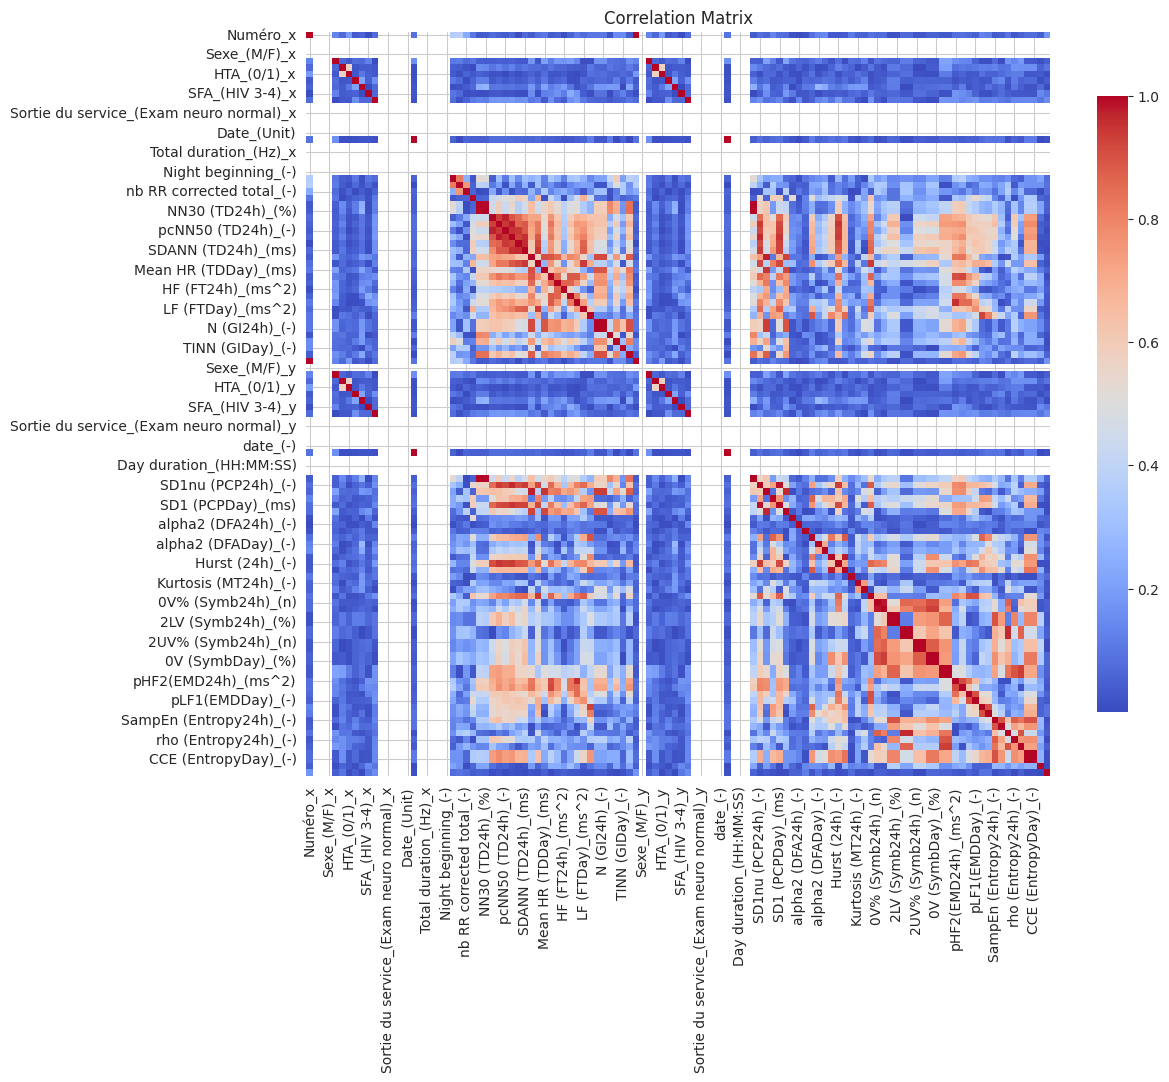

Columns to drop (correlation > 0.95): ['NN30 (TD24h)_(%)', 'pcNN50 (TD24h)_(-)', 'SDNN (TD24h)_(%)', 'SDANN (TD24h)_(ms)', 'N (GI24h)_(-)', 'Numéro_y', 'Tabac_(0/1)_y', 'Diabète_(0/1)_y', 'HTA_(0/1)_y', 'Maturation Pulm_(0/1)_y', 'Prématuré_(0/1)_y', 'SFA_(HIV 3-4)_y', 'R�a � la naissance_(LMPV)_y', 'Recorder_(-)_y', 'SD1SD2 (PCP24h)_(ms)', 'SD1nu (PCP24h)_(-)', 'SD2nu (PCP24h)_(%)', 'SD1 (PCPDay)_(ms)', 'SD2 (PCPDay)_(ms)', 'Beta 1f (Slope24h)_(-)', '1V (Symb24h)_(%)', '2LV (Symb24h)_(%)', '2UV (Symb24h)_(%)', 'MP (Symb24h)_(%)', '0V (SymbDay)_(%)', '1V (SymbDay)_(%)', 'pHF2(EMD24h)_(ms^2)', 'NCCE (Entropy24h)_(-)', 'CCE (EntropyDay)_(-)']
Removed 29 columns with correlation > 0.95.
Remaining columns: 85


,Numéro_x,Monogramme,DDN,Sexe_(M/F)_x,Tabac_(0/1)_x,Diabète_(0/1)_x,HTA_(0/1)_x,Maturation Pulm_(0/1)_x,Prématuré_(0/1)_x,SFA_(HIV 3-4)_x,...,pLF1(EMDDay)_(-),pLF2(EMDDay)_(ms^2),pHF1(EMDDay)_(ms^2),SampEn (Entropy24h)_(-),SE (Entropy24h)_(-),rho (Entropy24h)_(-),SE (EntropyDay)_(-),CE (EntropyDay)_(-),nan_(-),Note composite_(QIT)
0,2,JOG,22/09/2009,M,0,0.0,0.0,0.0,0,0.0,...,313.2697,0.64395,0.75278,0.78384,0.68736,0.51404,0.54852,0.46442,1.03030,95
1,4,DIM,28/09/2009,M,0,1.0,1.0,0.0,0,0.0,...,276.7408,0.67671,0.72976,0.98490,0.79444,0.68372,0.74641,0.55340,1.02470,78
2,5,ROM,30/09/2009,M,0,0.0,0.0,0.0,0,0.0,...,544.9800,0.63440,0.84077,1.07980,0.87908,0.77489,0.84948,0.60931,1.02420,100
3,12,CLT,16/10/2009,M,1,0.0,0.0,0.0,0,0.0,...,276.5562,0.73426,0.90111,0.91948,0.72021,0.67495,0.72628,0.52482,0.98072,90
4,14,GUS,21/10/2009,M,0,0.0,0.0,0.0,0,0.0,...,138.6239,1.07680,1.71490,0.72983,0.53368,0.57950,0.63318,0.43969,1.00200,90


In [137]:
#list of columns types with how many missing values
print('columns types with how many missing values:')
df_missing_types = df_merged_full_clean_80.dtypes
df_missing_types = df_missing_types.value_counts()
print(df_missing_types)

#with the analysis above, we can see that columns are usually of type object, and only 5 columns are of type float64. A lot of columns are of type object even though they should be numeric. We will convert all columns to numeric, and if they cannot be converted, we will drop them.
df_merged_full_clean_80_num = df_merged_full_clean_80.apply(pd.to_numeric, errors='coerce')
#we gotta keep columns that are not numeric, so we will create a new dataframe with only the non-numeric columns by selecting the columns that are fully NaN after the conversion to numeric, and we will keep them in a separate dataframe for later use. We will also print the list of non-numeric columns.
df_merged_full_non_numeric = df_merged_full_clean_80_num.isnull().all()
df_merged_full_non_numeric = df_merged_full_clean_80.loc[:, df_merged_full_non_numeric]
non_numeric_columns = df_merged_full_non_numeric.columns
print("non-numeric columns: ", non_numeric_columns)
print("non-numeric columns types: ", df_merged_full_non_numeric.dtypes)

display(df_merged_full_non_numeric.head())

print("columns converted to numeric: ", df_merged_full_clean_80_num.dtypes.value_counts())

def correlation_analysis(df, threshold=0.95):
    #correlation analysis & removal of highly correlated features (> 0.95)
    numeric_df = df.select_dtypes(include=[np.number])
    corr_matrix = numeric_df.corr().abs()
    #plot matrix as a heatmap but only for the ones that are above the threshold, and only for the upper triangle of the matrix
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", fmt=".2f", square=True, cbar_kws={"shrink": 0.8})
    plt.title("Correlation Matrix")
    plt.show()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [column for column in upper.columns if any(upper[column] > threshold)]
    print(f"Columns to drop (correlation > {threshold}): {to_drop}")
    df = df.drop(columns=to_drop)
    print(f"Removed {len(to_drop)} columns with correlation > {threshold}.")
    print(f"Remaining columns: {df.shape[1]}")
    return df

df_merged_full_clean_80_corr = correlation_analysis(df_merged_full_clean_80_num, threshold=0.95)

df_merged_full_clean_80_corr[non_numeric_columns] = df_merged_full_non_numeric

display(df_merged_full_clean_80_corr.head())


#### Variance threshold (remove near-zero variance features)



In [138]:
def remove_nearzero_variance(df, threshold=0.01):
    #remove near-zero variance features
    variance = df.var(numeric_only=True)
    to_remove = variance[variance < threshold].index
    list_removed = to_remove.tolist()
    print(f"Columns to remove (variance < {threshold}): {list_removed}")
    df = df.drop(columns=to_remove)
    print(f"Removed {len(to_remove)} columns with variance < {threshold}.")
    print(f"Remaining columns: {df.shape[1]}")
    return df


print("list of columns types:")
print(df_merged_full_clean_80_corr.dtypes.value_counts())
#good news, this has the right types

df_merged_full_clean_80_corr = remove_nearzero_variance(df_merged_full_clean_80_corr, threshold=0.01)

print("list of columns types after removing near-zero variance features:")
print(df_merged_full_clean_80_corr.dtypes.value_counts())


list of columns types:
float64    64
int64      11
object     10
Name: count, dtype: int64
Columns to remove (variance < 0.01): ['Pathologie neurologique_(Dilatation ventr)_x', 'Sortie du service_(Exam neuro normal)_x', "D�pression: prise d'IRS_(Labilit� cardiaq)_x", 'Filename_(0/1)_x', 'Date_(Unit)', 'Recorder_(-)_x', 'Night duration_x', 'Pathologie neurologique_(Dilatation ventr)_y', 'Sortie du service_(Exam neuro normal)_y', "D�pression: prise d'IRS_(Labilit� cardiaq)_y", 'Filename_(0/1)_y', 'date_(-)', 'Night duration_y', 'Centro�d (PCPDay)_(%)', 'alpha2 (DFADay)_(-)', 'H (DFADay)_(-)', 'AC (ACDC24h)_(-)', 'rho (Entropy24h)_(-)', 'CE (EntropyDay)_(-)', 'nan_(-)']
Removed 20 columns with variance < 0.01.
Remaining columns: 65
list of columns types after removing near-zero variance features:
float64    47
object     10
int64       8
Name: count, dtype: int64


#### Lasso/ElasticNet feature selection coefficient screening

this function will perform lasso/elasticnet feature selection and return the selected features. It will also print the ranking of features by absolute value of coefficients and plot a barplot of the coefficients.

What a feature has to have to be selected is that its coefficient has to be non-zero. The function will also print the number of selected features.

list of columns types before lasso/elasticnet feature selection:
float64    47
object     10
int64       8
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.509e+02, tolerance: 3.077e+00
  model = cd_fast.enet_coordinate_descent(


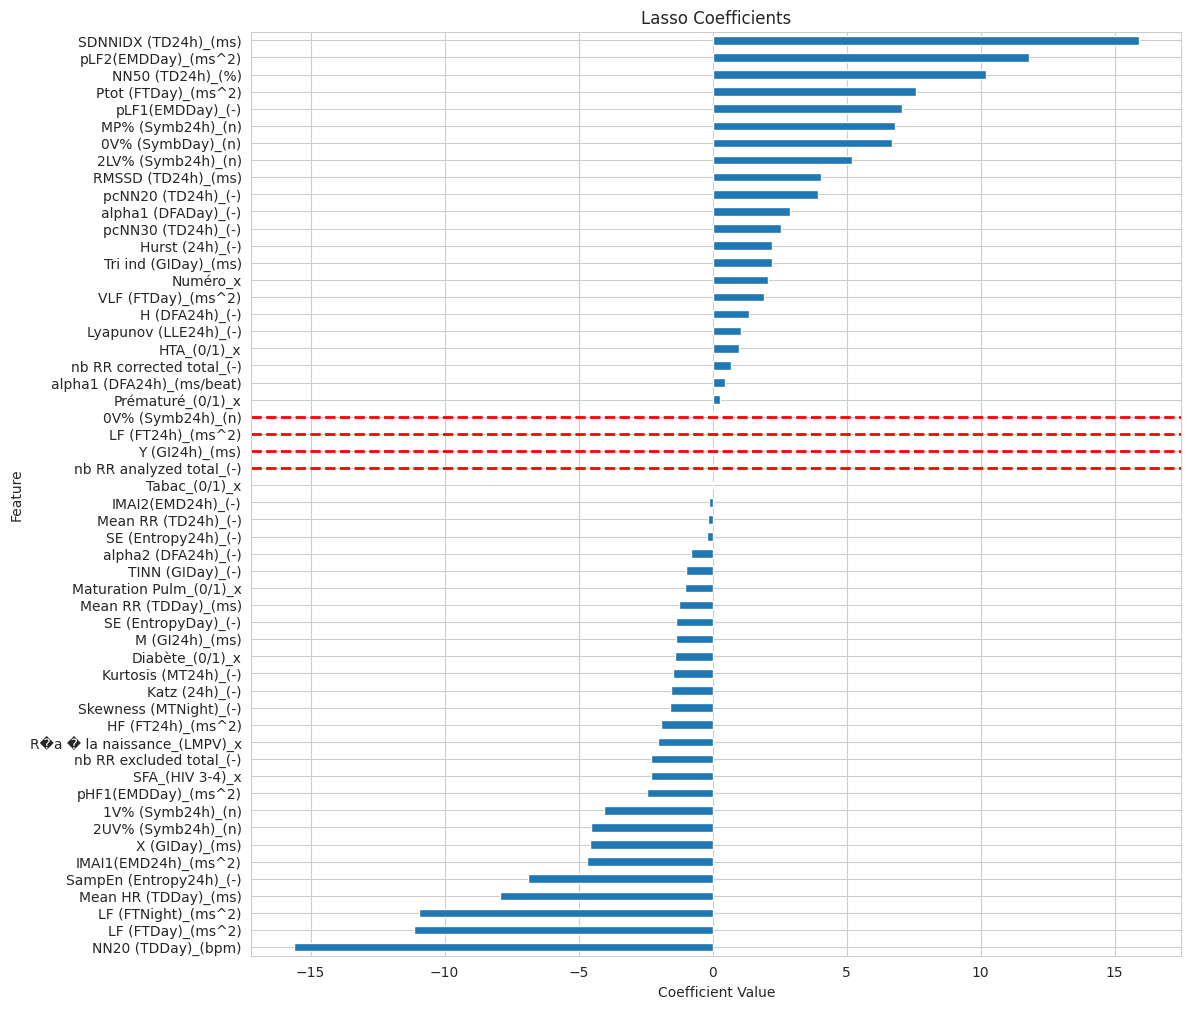

list of selected features after lasso/elasticnet feature selection:
['Numéro_x', 'Tabac_(0/1)_x', 'Diabète_(0/1)_x', 'HTA_(0/1)_x', 'Maturation Pulm_(0/1)_x', 'Prématuré_(0/1)_x', 'SFA_(HIV 3-4)_x', 'R�a � la naissance_(LMPV)_x', 'nb RR excluded total_(-)', 'nb RR corrected total_(-)', 'Mean RR (TD24h)_(-)', 'pcNN20 (TD24h)_(-)', 'pcNN30 (TD24h)_(-)', 'NN50 (TD24h)_(%)', 'RMSSD (TD24h)_(ms)', 'SDNNIDX (TD24h)_(ms)', 'Mean RR (TDDay)_(ms)', 'Mean HR (TDDay)_(ms)', 'NN20 (TDDay)_(bpm)', 'HF (FT24h)_(ms^2)', 'Ptot (FTDay)_(ms^2)', 'VLF (FTDay)_(ms^2)', 'LF (FTDay)_(ms^2)', 'LF (FTNight)_(ms^2)', 'M (GI24h)_(ms)', 'Tri ind (GIDay)_(ms)', 'TINN (GIDay)_(-)', 'X (GIDay)_(ms)', 'alpha1 (DFA24h)_(ms/beat)', 'alpha2 (DFA24h)_(-)', 'H (DFA24h)_(-)', 'alpha1 (DFADay)_(-)', 'Katz (24h)_(-)', 'Hurst (24h)_(-)', 'Skewness (MTNight)_(-)', 'Kurtosis (MT24h)_(-)', 'Lyapunov (LLE24h)_(-)', '1V% (Symb24h)_(n)', '2LV% (Symb24h)_(n)', '2UV% (Symb24h)_(n)', 'MP% (Symb24h)_(n)', '0V% (SymbDay)_(n)', 'IMAI1(E

,Numéro_x,Tabac_(0/1)_x,Diabète_(0/1)_x,HTA_(0/1)_x,Maturation Pulm_(0/1)_x,Prématuré_(0/1)_x,SFA_(HIV 3-4)_x,R�a � la naissance_(LMPV)_x,nb RR excluded total_(-),nb RR corrected total_(-),...,0V% (SymbDay)_(n),IMAI1(EMD24h)_(ms^2),IMAI2(EMD24h)_(-),pLF1(EMDDay)_(-),pLF2(EMDDay)_(ms^2),pHF1(EMDDay)_(ms^2),SampEn (Entropy24h)_(-),SE (Entropy24h)_(-),SE (EntropyDay)_(-),Note composite_(QIT)
0,2,0,0.0,0.0,0.0,0,0.0,0.0,147061,23170,...,182.0,127.7675,156.0060,313.2697,0.64395,0.75278,0.78384,0.68736,0.54852,95
1,4,0,1.0,1.0,0.0,0,0.0,0.0,153645,18275,...,173.0,280.8615,265.6012,276.7408,0.67671,0.72976,0.98490,0.79444,0.74641,78
2,5,0,0.0,0.0,0.0,0,0.0,0.0,160026,61,...,166.0,328.1180,423.9428,544.9800,0.63440,0.84077,1.07980,0.87908,0.84948,100
3,12,1,0.0,0.0,0.0,0,0.0,0.0,159470,613,...,173.0,233.7780,245.3804,276.5562,0.73426,0.90111,0.91948,0.72021,0.72628,90
4,14,0,0.0,0.0,0.0,0,0.0,0.0,163816,3598,...,177.0,298.6534,138.6944,138.6239,1.07680,1.71490,0.72983,0.53368,0.63318,90


(189, 51)


In [139]:
def lasso_elasticnet_feature_selection(df, target_variable, alpha=0.01, l1_ratio=0.5):
    #lasso/elasticnet feature selection coefficient screening
    X = df.drop(columns=[target_variable])
    y = df[target_variable]
    
    #impute missing values with mean for numeric columns
    X = X.fillna(X.mean(numeric_only=True))
    
    #standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X.select_dtypes(include=[np.number]))
    
    #fit lasso model
    lasso = Lasso(alpha=alpha)
    lasso.fit(X_scaled, y)
    
    #get coefficients
    coef = pd.Series(lasso.coef_, index=X.select_dtypes(include=[np.number]).columns)
    
    #select features with non-zero coefficients
    selected_features = coef[coef != 0].index.tolist()
    
    #barplot of coefficients and draw full horizontal red barplot for features that haven't been selected (i.e. have a coefficient of 0)
    plt.figure(figsize=(12, 12))
    coef.sort_values().plot(kind="barh")
    plt.title("Lasso Coefficients")
    plt.xlabel("Coefficient Value")
    plt.ylabel("Feature")
    for position, feature in enumerate(coef.sort_values().index):
        if coef.sort_values()[feature] == 0:
            plt.axhline(
                y=position,
                color="red",
                linestyle="--",
                linewidth=2
            )
    plt.show()
    
    return selected_features

print("list of columns types before lasso/elasticnet feature selection:")
print(df_merged_full_clean_80_corr.dtypes.value_counts())

selected_features = lasso_elasticnet_feature_selection(df_merged_full_clean_80_corr, AFTER_MERGE_TARGET_VARIABLE, alpha=0.01, l1_ratio=0.5)

print("list of selected features after lasso/elasticnet feature selection:")
print(selected_features)

print("Number of selected features:")
print(len(selected_features))

df_merged_lasso_selected = df_merged_full_clean_80_corr[selected_features + [AFTER_MERGE_TARGET_VARIABLE]]

display(df_merged_lasso_selected.head())

print(df_merged_lasso_selected.shape)

#### Taking off unrelated features 

In [140]:
df_took_off = df_merged_lasso_selected.drop(columns=["Numéro_x"])

#taking off all note_composite columns except for the target variable AFTER_MERGE_TARGET_VARIABLE
columns_to_drop = [col for col in df_took_off.columns if "Note composite" in col and col != AFTER_MERGE_TARGET_VARIABLE]
df_took_off = df_took_off.drop(columns=columns_to_drop)

display(df_took_off.head())


,Tabac_(0/1)_x,Diabète_(0/1)_x,HTA_(0/1)_x,Maturation Pulm_(0/1)_x,Prématuré_(0/1)_x,SFA_(HIV 3-4)_x,R�a � la naissance_(LMPV)_x,nb RR excluded total_(-),nb RR corrected total_(-),Mean RR (TD24h)_(-),...,0V% (SymbDay)_(n),IMAI1(EMD24h)_(ms^2),IMAI2(EMD24h)_(-),pLF1(EMDDay)_(-),pLF2(EMDDay)_(ms^2),pHF1(EMDDay)_(ms^2),SampEn (Entropy24h)_(-),SE (Entropy24h)_(-),SE (EntropyDay)_(-),Note composite_(QIT)
0,0,0.0,0.0,0.0,0,0.0,0.0,147061,23170,1866,...,182.0,127.7675,156.0060,313.2697,0.64395,0.75278,0.78384,0.68736,0.54852,95
1,0,1.0,1.0,0.0,0,0.0,0.0,153645,18275,1052,...,173.0,280.8615,265.6012,276.7408,0.67671,0.72976,0.98490,0.79444,0.74641,78
2,0,0.0,0.0,0.0,0,0.0,0.0,160026,61,79,...,166.0,328.1180,423.9428,544.9800,0.63440,0.84077,1.07980,0.87908,0.84948,100
3,1,0.0,0.0,0.0,0,0.0,0.0,159470,613,27,...,173.0,233.7780,245.3804,276.5562,0.73426,0.90111,0.91948,0.72021,0.72628,90
4,0,0.0,0.0,0.0,0,0.0,0.0,163816,3598,486,...,177.0,298.6534,138.6944,138.6239,1.07680,1.71490,0.72983,0.53368,0.63318,90


#### Standardization of features on training data

In [141]:
def std_feature_traindata(X_train):
    #standardize features on training data
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    return X_train_scaled, scaler

df_merged_lasso_selected_numeric = df_took_off.select_dtypes(include=[np.number])
df_merged_lasso_selected_non_numeric = df_took_off.select_dtypes(exclude=[np.number])

target_variable = AFTER_MERGE_TARGET_VARIABLE
try:
    X = df_merged_lasso_selected_numeric.drop(columns=[target_variable])
    y = df_merged_lasso_selected_numeric[target_variable]
    X_train_scaled, scaler = std_feature_traindata(X)
except KeyError as e:
    print(f"Error: {e}")
    
    
nan_counts = X.isna().sum()
#print count and their types
print("Count of NaN values in each column:\n", nan_counts[nan_counts > 0])
print("Count of NaN values in each column types:\n", X.dtypes[nan_counts > 0])




Count of NaN values in each column:
 Diabète_(0/1)_x                7
HTA_(0/1)_x                    2
Maturation Pulm_(0/1)_x        1
SFA_(HIV 3-4)_x                1
R�a � la naissance_(LMPV)_x    2
pcNN20 (TD24h)_(-)             2
pcNN30 (TD24h)_(-)             2
NN50 (TD24h)_(%)               2
RMSSD (TD24h)_(ms)             2
SDNNIDX (TD24h)_(ms)           2
Mean RR (TDDay)_(ms)           2
Mean HR (TDDay)_(ms)           2
NN20 (TDDay)_(bpm)             2
HF (FT24h)_(ms^2)              2
Ptot (FTDay)_(ms^2)            2
VLF (FTDay)_(ms^2)             2
LF (FTDay)_(ms^2)              2
LF (FTNight)_(ms^2)            2
M (GI24h)_(ms)                 2
Tri ind (GIDay)_(ms)           2
TINN (GIDay)_(-)               2
X (GIDay)_(ms)                 2
alpha1 (DFA24h)_(ms/beat)      2
alpha2 (DFA24h)_(-)            2
H (DFA24h)_(-)                 2
alpha1 (DFADay)_(-)            2
Katz (24h)_(-)                 9
Hurst (24h)_(-)                9
Skewness (MTNight)_(-)         2
Kurtos

#### Impute missing values with mean on training data


In [142]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean') #impute missing values with mean for numeric columns
X_train_imputed = imputer.fit_transform(X_train_scaled)

print("nan_counts after imputation: ", np.isnan(X_train_imputed).sum()  )

nan_counts after imputation:  0


#### Dataset get-off filtering

In [143]:
### take off the columns that are related to the WPPSI results

df_merged_lasso_selected_no_wppsi = df_merged_lasso_selected

#### replot correlation matrix after feature selection

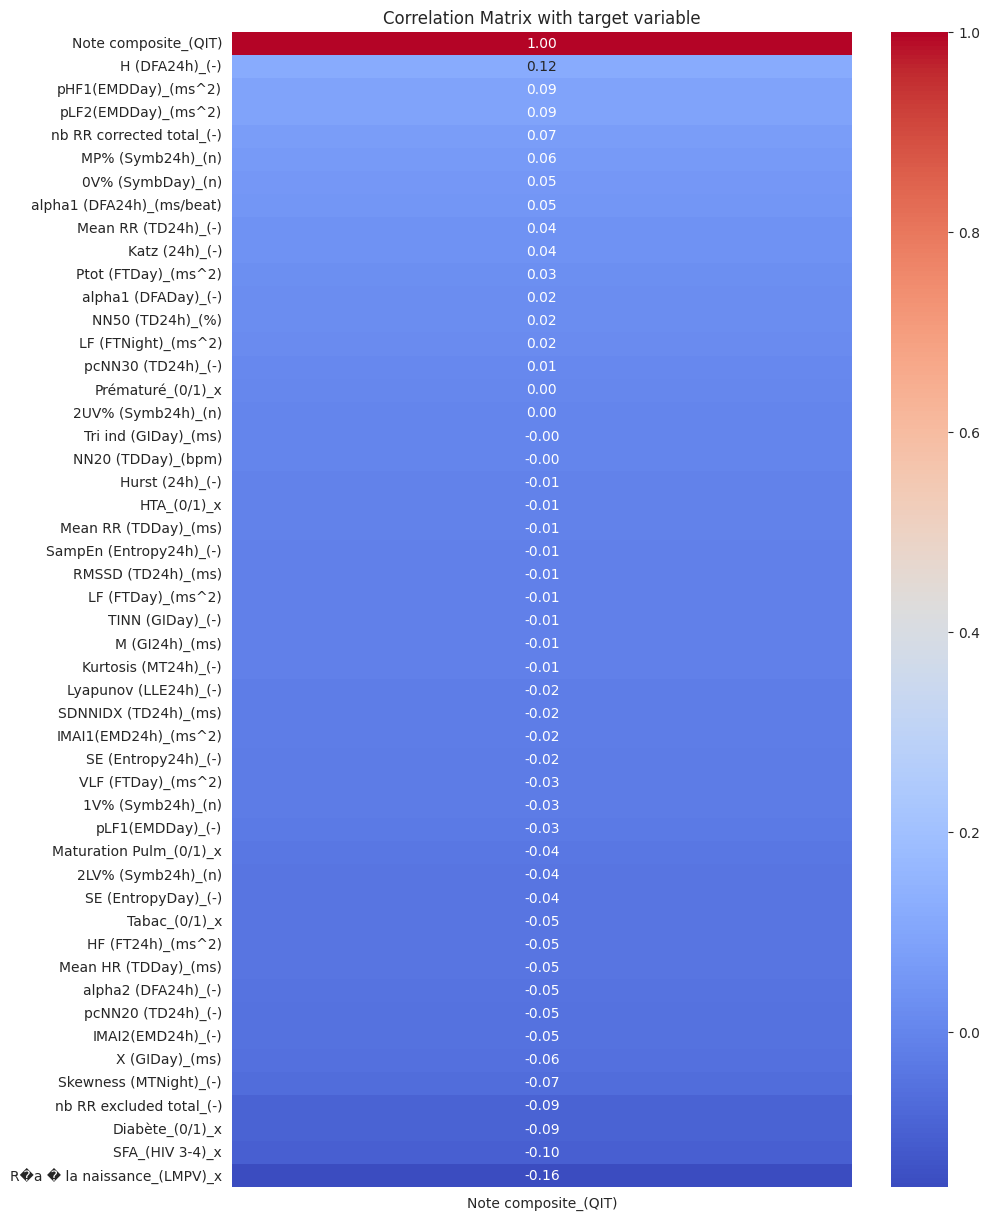

In [147]:
#we use X_train_imputed and y for plots, correlation ranking with y

plt.figure(figsize=(10, 15))
#compute correlation matrix with y
sns.heatmap(df_took_off.corr()[[AFTER_MERGE_TARGET_VARIABLE]].sort_values(by=AFTER_MERGE_TARGET_VARIABLE, ascending=False), annot=True, cmap="coolwarm", fmt=".2f", square=False, cbar_kws={"shrink": 1.0})
plt.title("Correlation Matrix with target variable")
plt.savefig(os.path.join(write_path_plots, "correlation_matrix_with_target_variable.png"), dpi=300)
plt.show()

#save plot as png at path WRITE_PATH_PLOTS

write_path_plots = os.getenv("WRITE_PATH_PLOTS")
if not os.path.exists(write_path_plots):
    os.makedirs(write_path_plots)
    print(f"Created plots directory: {write_path_plots}")



#save correlation matrix as csv at path WRITE_PATH_PLOTS
corr_matrix = df_took_off.corr()[[AFTER_MERGE_TARGET_VARIABLE]]
corr_matrix.to_csv(os.path.join(write_path, "correlation_matrix_with_target_variable.csv"))

#### Save dataset in data folder for future use (locally, .gitignore)

In [ ]:
write_path = os.getenv("WRITE_PATH")

#save the dataframe to a csv file in the data folder for future use (locally, .gitignore)

X_train_imputed_df = pd.DataFrame(X_train_imputed, columns=X.columns)
X_and_Y = pd.concat([X_train_imputed_df, y.reset_index(drop=True)], axis=1)

#force replacement of the file if it already exists

if os.path.exists(os.path.join(write_path, "df_merged_lasso_selected_imputed.csv")):
    os.remove(os.path.join(write_path, "df_merged_lasso_selected_imputed.csv"))
X_and_Y.to_csv(os.path.join(write_path, "df_merged_lasso_selected_imputed.csv"), index=False)


### Regression!

#### ElasticNet regression with cross-validation

time with colab = 28s

In [ ]:
# parameters

#alpha is the regularization strength, must be a positive float. 

#alpha would be logspace from -4 to 1

alpha_values = np.logspace(-4, 1, 50)

l1_ratio_values = np.linspace(0, 1, 10) #[0.1, 0.3, 0.5, 0.7, 0.9]

models_path = os.getenv("MODELS_PATH")

ElasticNet is a linear regression model that combines L1 and L2 regularization. It is useful when there are multiple features that are correlated with each other. The model has two hyperparameters: alpha (the regularization strength) and l1_ratio (the mix between L1 and L2 regularization).

In [ ]:
# model
from sklearn.base import clone

from sklearn.pipeline import make_pipeline
model = ElasticNet()

#import data from the csv file we just saved, and split it into X and y

df_merged_lasso_selected = pd.read_csv(os.path.join(write_path, "df_merged_lasso_selected_imputed.csv"))
X_train = df_merged_lasso_selected.drop(columns=[target_variable])
y_train = df_merged_lasso_selected[target_variable]

from sklearn.model_selection import RandomizedSearchCV , KFold, RandomizedSearchCV

pipeline = make_pipeline(
    StandardScaler(),
    ElasticNet(max_iter=10000, random_state=42)
)

param_grid = {
    "elasticnet__alpha": alpha_values,
    "elasticnet__l1_ratio": l1_ratio_values
}

grid_search = RandomizedSearchCV(
    pipeline,
    param_grid,
    n_iter=50,  # Number of parameter settings that are sampled. n_iter trades off runtime vs quality of the solution.
    scoring="neg_mean_absolute_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print(grid_search.best_params_)
print(-grid_search.best_score_)

joblib.dump(best_model, os.path.join(models_path, "best_elasticnet_model.joblib"))


#### Random Forest regression with cross-validation

time with colab = 12m 21s

In [ ]:
#parameters

n_estimators = [200, 500]
max_depth = [None, 3,5,7]
min_samples_split = [5,10,20]
max_features = ["sqrt", "log2"]


In [ ]:
model = RandomForestRegressor()

pipeline_rf = make_pipeline(
    StandardScaler(),
    RandomForestRegressor(random_state=42)
)

param_grid_rf = {
    "randomforestregressor__n_estimators": n_estimators,
    "randomforestregressor__max_depth": max_depth,
    "randomforestregressor__min_samples_split": min_samples_split,
    "randomforestregressor__max_features": max_features
}

grid_search_rf = RandomizedSearchCV (
    pipeline_rf,
    param_grid_rf,
    n_iter=50,  # Number of parameter settings that are sampled. n_iter trades off runtime vs quality of the solution.
    scoring="neg_mean_absolute_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=1 #n_jobs=1 means using all processors, you can change it to a specific number if you want to limit the number of processors used
)

grid_search_rf.fit(X_train, y_train)

best_model_rf = grid_search_rf.best_estimator_
print(grid_search_rf.best_params_)
print(-grid_search_rf.best_score_)

joblib.dump(best_model_rf, os.path.join(models_path, "best_randomforest_model.joblib"))


#### LightGBM regression with cross-validation

time with colab = 1m 37s

In [ ]:
#params
n_estimators = [100, 300]
learning_rate = [0.01, 0.05, 0.1]
max_depth = [3, 5, 7]
min_child_samples = [1,5]
alpha = [0.001, 0.1, 0.5, 1.0]
reg_lambda = [0.0, 0.1, 0.5, 1.0]

In [ ]:
#model training

from lightgbm import LGBMRegressor

model = LGBMRegressor(random_state=42, objective='regression', n_jobs=1, verbosity=-1)

pipeline_lgbm = make_pipeline(
    LGBMRegressor(random_state=42, objective='regression', n_jobs=1, verbosity=-1)
)

param_grid_lgbm = {
    "lgbmregressor__n_estimators": n_estimators,
    "lgbmregressor__learning_rate": learning_rate,
    "lgbmregressor__max_depth": max_depth,
    "lgbmregressor__min_child_samples": min_child_samples,
    "lgbmregressor__alpha": alpha, #alpha is the L1 regularization term on weights, must be a positive float. 
    "lgbmregressor__reg_lambda": reg_lambda #reg_lambda is the L2 regularization term on weights, must be a positive float. 
}

grid_search_lgbm = RandomizedSearchCV(
    pipeline_lgbm,
    param_grid_lgbm,
    n_iter=50,  # Number of parameter settings that are sampled. n_iter trades off runtime vs quality of the solution.
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=1
)

grid_search_lgbm.fit(X_train, y_train)

best_model_lgbm = grid_search_lgbm.best_estimator_
print(grid_search_lgbm.best_params_)
print(-grid_search_lgbm.best_score_)

joblib.dump(best_model_lgbm, os.path.join(models_path, "best_lightgbm_model.joblib"))

#### XGBoost regression with cross-validation
time with colab = 2min

In [ ]:
#params

n_estimators = [100, 300]
learning_rate = [0.01, 0.05, 0.1]
max_depth = [3, 5, 7]
min_child_weight = [1, 5]
subsample = [0.8, 1.0]
colsample_bytree = [0.8, 1.0]
reg_alpha = [0.0,0.1,1.0]
reg_lambda = [0.1,1.0,10.0]

In [ ]:
#model training

from xgboost import XGBRegressor

pipeline_xgb = make_pipeline(
    XGBRegressor(random_state=42, objective='reg:squarederror', n_jobs=1, verbosity=0, eval_metric='mae')
)

param_grid_xgb = {
    "xgbregressor__n_estimators": n_estimators,
    "xgbregressor__learning_rate": learning_rate,
    "xgbregressor__max_depth": max_depth,
    "xgbregressor__min_child_weight": min_child_weight,
    "xgbregressor__subsample": subsample,
    "xgbregressor__colsample_bytree": colsample_bytree,
    "xgbregressor__reg_alpha": reg_alpha,
    "xgbregressor__reg_lambda": reg_lambda,
}

grid_search_xgb = RandomizedSearchCV (
    pipeline_xgb,
    param_grid_xgb,
    n_iter=50,  # Number of parameter settings that are sampled. n_iter trades off runtime vs quality of the solution.
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=1
)

grid_search_xgb.fit(X_train, y_train)

best_model_xgb = grid_search_xgb.best_estimator_
print(grid_search_xgb.best_params_)
print(-grid_search_xgb.best_score_)

joblib.dump(best_model_xgb, os.path.join(models_path, "best_xgboost_model.joblib"))

#### Support Vector Regression (SVR) with cross-validation

time with colab = 31s

In [ ]:
#params

C = [0.1, 1, 10, 100]
epsilon = [0.01, 0.1, 1.0]
kernel = ['rbf', 'linear']
gamma = ['scale', 'auto']

In [ ]:
#model training

from sklearn.svm import SVR

pipeline_svr = make_pipeline(
    StandardScaler(),
    SVR()
)

param_grid_svr = {
    "svr__C": C,
    "svr__epsilon": epsilon,
    "svr__kernel": kernel,
    "svr__gamma": gamma
}

grid_search_svr = RandomizedSearchCV(
    pipeline_svr,
    param_grid_svr,
    n_iter=50,  # Number of parameter settings that are sampled. n_iter trades off runtime vs quality of the solution.
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=1,
    error_score='raise'
)

grid_search_svr.fit(X_train, y_train)

best_model_svr = grid_search_svr.best_estimator_
print(grid_search_svr.best_params_)
print(-grid_search_svr.best_score_)

joblib.dump(best_model_svr, os.path.join(models_path, "best_svr_model.joblib"))

#### Summary of results

All models were trained to predict the target variable using the preprocessed dataset. Hyperparameters were selected using 5-fold cross-validation, with mean absolute error (MAE) as the optimization metric. The final model was refitted using the best hyperparameter combination.

| Model | Preprocessing | Main hyperparameters tuned | Evaluation |
|---|---|---|---|
| ElasticNet | Median imputation + standardization | `alpha`, `l1_ratio` | 5-fold CV |
| LightGBM | Imputation; scaling not required | `n_estimators`, `learning_rate`, `max_depth`, `min_child_samples`, `reg_alpha`, `reg_lambda` | 5-fold CV |
| XGBoost | Imputation; scaling not required | `n_estimators`, `learning_rate`, `max_depth`, `min_child_weight`, `subsample`, `reg_alpha`, `reg_lambda` | 5-fold CV |
| SVR | Median imputation + standardization | `C`, `epsilon`, `kernel`, `gamma` | 5-fold CV |

The models were compared using MAE, MSE, RMSE, and \(R^2\). Lower MAE, MSE, and RMSE indicate better performance, whereas higher \(R^2\) indicates better explanatory performance.

The target variable was `Note composite_(QIT)`. Missing predictor values were imputed and selected features were used for modelling. Each model was evaluated using 5-fold cross-validation, with hyperparameters selected by minimizing mean absolute error (MAE).

| Model | Best hyperparameters | Cross-validated MAE |
|---|---|---:|
| ElasticNet | `alpha = 6.2506`, `l1_ratio = 0.6667` | **10.3853** |
| SVR | `C = 0.1`, `epsilon = 0.01`, `kernel = rbf`, `gamma = scale` | **10.4125** |
| XGBoost | `n_estimators = 100`, `learning_rate = 0.01`, `max_depth = 7`, `min_child_weight = 1`, `subsample = 0.8`, `colsample_bytree = 1.0`, `reg_alpha = 1.0`, `reg_lambda = 10.0` | **10.5920** |
| Random Forest | `n_estimators = 200`, `min_samples_split = 20`, `max_features = log2`, `max_depth = 3` | **10.6362** |
| LightGBM | `alpha = 0.001`, `learning_rate = 0.01`, `max_depth = 3`, `min_child_samples = 5`, `n_estimators = 300`, `reg_lambda = 1.0` | **11.1753** |

ElasticNet achieved the lowest cross-validated MAE (**10.3853**), followed by SVR (**10.4125**) and XGBoost (**10.5920**). Random Forest and LightGBM performed slightly worse, with MAEs of **10.6362** and **11.1753**, respectively. Therefore, ElasticNet was the best-performing model according to cross-validated MAE.

### Standerdized evaluation across all models and all IQ targets

In [ ]:


model_specs = {
    "ElasticNet": {
        "estimator": make_pipeline(
            StandardScaler(),
            ElasticNet(max_iter=10000, random_state=42)
        ),
        "params": {
            "elasticnet__alpha": np.logspace(-4, 1, 20),
            "elasticnet__l1_ratio": [0.1, 0.5, 0.9]
        }
    },

    "RandomForest": {
        "estimator": RandomForestRegressor(random_state=42, n_jobs=1),
        "params": {
            "n_estimators": [200, 500],
            "max_depth": [None, 3, 5, 7],
            "min_samples_split": [5, 10, 20],
            "max_features": ["sqrt", "log2"]
        }
    },

    "LightGBM": {
        "estimator": LGBMRegressor(
            objective="regression",
            random_state=42,
            n_jobs=1,
            verbosity=-1
        ),
        "params": {
            "n_estimators": [100, 300],
            "learning_rate": [0.01, 0.05, 0.1],
            "max_depth": [3, 5, 7],
            "min_child_samples": [1, 5],
            "reg_alpha": [0.001, 0.1, 0.5],
            "reg_lambda": [0.0, 0.1, 1.0]
        }
    },

    "XGBoost": {
        "estimator": XGBRegressor(
            objective="reg:squarederror",
            random_state=42,
            n_jobs=1,
            eval_metric="mae"
        ),
        "params": {
            "n_estimators": [100, 300],
            "learning_rate": [0.01, 0.05, 0.1],
            "max_depth": [3, 5, 7],
            "min_child_weight": [1, 5],
            "subsample": [0.8, 1.0],
            "reg_alpha": [0.0, 0.1, 1.0],
            "reg_lambda": [0.1, 1.0, 10.0]
        }
    },

    "SVR": {
        "estimator": make_pipeline(
            StandardScaler(),
            SVR()
        ),
        "params": {
            "svr__C": [0.1, 1, 10, 100],
            "svr__epsilon": [0.01, 0.1, 1.0],
            "svr__kernel": ["rbf", "linear"],
            "svr__gamma": ["scale", "auto"]
        }
    }
}

warning: time to execute this cell: 75min~

In [ ]:
#import pipeline
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedKFold,
    cross_validate
)
#cv strategy: 10-fold cross-validation with shuffle and random_state=42, 10 repeats, target is QIT (primary target), QIV,QIP,NCL
%dotenv

AFTER_MERGE_TARGET_VARIABLE = os.getenv("AFTER_MERGE_TARGET_VARIABLE")
write_path = os.getenv("WRITE_PATH")
df_main = pd.read_csv(os.path.join(write_path, "df_merged_lasso_selected_imputed.csv"))

X = df_main.drop(columns=[AFTER_MERGE_TARGET_VARIABLE])
y = df_main[[AFTER_MERGE_TARGET_VARIABLE]]

scoring_metrics = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

# this would take a huge amount of time to run
# inner_cv = RepeatedKFold(n_splits=10, n_repeats=10, random_state=42)
# outer_cv = RepeatedKFold(n_splits=10, n_repeats=10, random_state=42)

inner_cv = KFold(n_splits=5, shuffle=True, random_state=42)
outer_cv = RepeatedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

scoring = scoring_metrics

def nested_cv_evaluation(estimator, param_grid, X, y):
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_grid,
        n_iter=50,  # Number of parameter settings that are sampled. n_iter trades off runtime vs quality of the solution.
        scoring="neg_mean_absolute_error",
        cv=inner_cv,
        n_jobs=1,
        error_score="raise",
        random_state=42
    )

    scores = cross_validate(
        search,
        X,
        y,
        cv=outer_cv,
        scoring=scoring,
        n_jobs=1
    )

    mae = -scores["test_MAE"]
    mse = -scores["test_MSE"]
    rmse = -scores["test_RMSE"]
    r2 = scores["test_R2"]

    return {
        "MAE_mean": mae.mean(),
        "MAE_std": mae.std(),
        "MSE_mean": mse.mean(),
        "MSE_std": mse.std(),
        "RMSE_mean": rmse.mean(),
        "RMSE_std": rmse.std(),
        "R2_mean": r2.mean(),
        "R2_std": r2.std()
    }
    
    
results = {}

for model_name, spec in model_specs.items():
    print(f"Evaluating {model_name}...")
    results[model_name] = nested_cv_evaluation(spec["estimator"], spec["params"], X, y[AFTER_MERGE_TARGET_VARIABLE])
    print(f"Results for {model_name}: {results[model_name]}")
    
results_df = pd.DataFrame(results).T
results_df.to_csv(os.path.join(write_path, "model_evaluation_results.csv"), index=True
)
display(results_df)

### Nested cross-validation results

The models were evaluated using nested cross-validation. Results are reported as mean ± standard deviation across the outer folds.

| Model | MAE | MSE | RMSE | R² |
|---|---:|---:|---:|---:|
| ElasticNet | 10.440 ± 1.149 | 167.929 ± 40.140 | 12.864 ± 1.566 | −0.050 ± 0.050 |
| Random Forest | 10.595 ± 1.213 | 173.164 ± 40.331 | 13.065 ± 1.569 | −0.084 ± 0.055 |
| LightGBM | 10.677 ± 1.262 | 173.606 ± 39.493 | 13.086 ± 1.541 | −0.089 ± 0.076 |
| XGBoost | 10.597 ± 1.244 | 172.217 ± 40.302 | 13.027 ± 1.583 | −0.078 ± 0.085 |
| SVR | 10.446 ± 1.107 | 167.461 ± 37.390 | 12.857 ± 1.470 | −0.050 ± 0.047 |

### Interpretation

ElasticNet achieved the lowest MAE (10.440), while SVR achieved the lowest MSE (167.461) and RMSE (12.857). ElasticNet had the highest R² (−0.050), although it was almost identical to SVR (−0.050).

All models obtained negative R² values. This indicates that they performed worse than a baseline model that always predicts the mean target value. Therefore, none of the models demonstrates useful predictive performance on this evaluation. The differences between the models are small compared with their standard deviations, so there is no clear practical advantage among them. These results suggest that the current features and modelling approach do not adequately predict the target variable.

#### Plots

packages

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import os


import seaborn as sns
import numpy as np

import os
os.chdir("/content/international-project/FSIQ-from-ECG/GroupA/Mateo")

#line magic function not found: run this line 
# %load_ext dotenv
%reload_ext dotenv
%dotenv

plot of MAE

In [ ]:
#bar plot of mae per model with error bars for std, sorted by mae mean

#import csv
write_path = os.getenv("WRITE_PATH")
print("write_path: ", write_path)

results_df_sorted = pd.read_csv(os.path.join(write_path, "model_evaluation_results.csv"), index_col=0
).sort_values(by="MAE_mean", ascending=True)

write_path_plots = os.getenv("WRITE_PATH_PLOTS")

if not os.path.exists(write_path_plots):
    os.makedirs(write_path_plots)
    print(f"Created plots directory: {write_path_plots}")

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(results_df_sorted))
ax.bar(
    x,
    results_df_sorted["MAE_mean"].to_numpy(),
    yerr=results_df_sorted["MAE_std"].to_numpy(),
    capsize=5,
    color=plt.cm.viridis(np.linspace(0.15, 0.85, len(x)))
)

ax.set_xticks(x)
ax.set_xticklabels(results_df_sorted.index, rotation=45)
ax.set_title("Model Comparison: Mean Absolute Error (MAE)")
ax.set_xlabel("Models")
ax.set_ylabel("Mean Absolute Error (MAE)")

fig.tight_layout()
fig.savefig(
    os.path.join(write_path_plots, "model_comparison_mae.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Bar plot of R² per model with baseline R² = 0

In [ ]:
#bar plot of R² per model with basel

ax = results_df_sorted["R2_mean"].plot.bar(
    yerr=results_df_sorted["R2_std"],
    capsize=5,
    color=plt.cm.viridis(np.linspace(0.15, 0.85, len(results_df_sorted))),
    figsize=(10, 6)
)

plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.title("Model Comparison: R² Score")
plt.xlabel("Models")
plt.ylabel("R² Score")

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    os.path.join(write_path_plots, "model_comparison_r2.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Box plots of fold-level scores

In [ ]:
#box plots of fold scores for each model, for MAE, MSE, RMSE, R²

boxplot_metrics = ["MAE", "MSE", "RMSE", "R2"]

x = np.arange(len(results_df_sorted))
y = results_df_sorted[["MAE_mean", "MSE_mean", "RMSE_mean", "R2_mean"]].to_numpy()

plt.figure(figsize=(12, 8))
for i, metric in enumerate(boxplot_metrics):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(
        x=results_df_sorted.index,
        y=y[:, i],
    )
    plt.title(f"Model Comparison: {metric}")
    plt.xlabel("Models")
    plt.ylabel(metric)
    plt.xticks(rotation=45)
    
plt.tight_layout()
plt.savefig(
    os.path.join(write_path_plots, "model_comparison_boxplots.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()



## SHAP training and evaluation

In [117]:
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    KFold
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [148]:
def train_models_with_shap_feature_counts(
    shap_model,
    evaluation_model,
    X,
    y,
    model_name,
    test_size=0.2,
    random_state=42,
    max_features=8
):
    """
    Rank features with SHAP using one model, then train and evaluate
    another model using the top 1 to max_features features.

    The SHAP model is used only for feature ranking.
    The evaluation model is re-tuned separately for every feature count.
    """

    if not isinstance(X, pd.DataFrame):
        raise TypeError("X must be a pandas DataFrame.")

    if not isinstance(y, pd.Series):
        y = pd.Series(y)

    if len(X) != len(y):
        raise ValueError("X and y must contain the same number of rows.")

    if X.isna().any().any():
        raise ValueError(
            "X contains missing values. Impute X before calling this function."
        )

    if max_features < 1 or max_features > X.shape[1]:
        raise ValueError(
            "max_features must be between 1 and the number of columns in X."
        )

    # Split once. The test data remains untouched until final evaluation.
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=random_state
    )

    print(f"\nModel evaluated: {model_name}")
    print(f"Total observations: {len(X)}")
    print(f"Training observations: {len(X_train)}")
    print(f"Testing observations: {len(X_test)}")
    print(f"Available features: {X.shape[1]}")

    # ---------------------------------------------------------------
    # 1. Train a separate model for SHAP feature ranking
    # ---------------------------------------------------------------

    ranking_model = clone(shap_model)
    ranking_model.fit(X_train, y_train)

    # SHAP explains the complete model, including any preprocessing
    # contained inside a pipeline.
    masker = shap.maskers.Independent(
        X_train,
        max_samples=len(X_train)
    )

    explainer = shap.Explainer(
        ranking_model.predict,
        masker
    )

    shap_output = explainer(X_train)
    shap_values = shap_output.values

    if shap_values.ndim == 3:
        shap_values = np.mean(np.abs(shap_values), axis=2)

    mean_absolute_shap = np.abs(shap_values).mean(axis=0)

    shap_importance = (
        pd.Series(
            mean_absolute_shap,
            index=X_train.columns,
            name="mean_absolute_shap"
        )
        .sort_values(ascending=False)
    )

    print("\nSHAP feature ranking:")
    display(shap_importance.to_frame())

    ranked_features = shap_importance.index.tolist()

    # ---------------------------------------------------------------
    # 2. Train and evaluate models with the top 1 to 5 features
    # ---------------------------------------------------------------

    results = []
    trained_models = {}
    feature_sets = {}

    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=random_state
    )

    for number_of_features in range(1, max_features + 1):

        selected_features = ranked_features[:number_of_features]

        print(
            f"\nTraining {model_name} with "
            f"the top {number_of_features} feature(s):"
        )
        print(selected_features)

        # Create a new model for this feature count.
        model_to_tune = clone(evaluation_model)

        # If the evaluation model is ElasticNet, tune its parameters
        # again because the optimal regularization changes when features
        # are removed.
        if isinstance(model_to_tune, ElasticNet):
            model_pipeline = make_pipeline(
                StandardScaler(),
                ElasticNet(
                    max_iter=10000,
                    random_state=random_state
                )
            )

            parameter_grid = {
                "elasticnet__alpha": np.logspace(-4, 1, 50),
                "elasticnet__l1_ratio": np.linspace(0.1, 1.0, 21)
            }

        else:
            model_pipeline = model_to_tune
            parameter_grid = {}

        if parameter_grid:
            search = GridSearchCV(
                estimator=model_pipeline,
                param_grid=parameter_grid,
                scoring="neg_mean_absolute_error",
                cv=cv,
                n_jobs=-1
            )

            search.fit(
                X_train[selected_features],
                y_train
            )

            model = search.best_estimator_
            best_parameters = search.best_params_

        else:
            model = model_pipeline
            model.fit(
                X_train[selected_features],
                y_train
            )
            best_parameters = {}

        predictions = model.predict(
            X_test[selected_features]
        )

        mae = mean_absolute_error(y_test, predictions)
        rmse = np.sqrt(mean_squared_error(y_test, predictions))
        r2 = r2_score(y_test, predictions)

        number_of_nonzero_coefficients = None

        if hasattr(model, "named_steps"):
            final_estimator = list(model.named_steps.values())[-1]

            if hasattr(final_estimator, "coef_"):
                number_of_nonzero_coefficients = np.count_nonzero(
                    final_estimator.coef_
                )

        results.append({
            "model": model_name,
            "number_of_features": number_of_features,
            "features": selected_features,
            "best_parameters": best_parameters,
            "nonzero_coefficients": number_of_nonzero_coefficients,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        trained_models[number_of_features] = model
        feature_sets[number_of_features] = selected_features

        print(f"Best parameters: {best_parameters}")
        print(f"Non-zero coefficients: {number_of_nonzero_coefficients}")
        print(f"MAE: {mae:.4f}")
        print(f"RMSE: {rmse:.4f}")
        print(f"R2: {r2:.4f}")

    results = pd.DataFrame(results)

    return (
        results,
        shap_importance,
        trained_models,
        feature_sets
    )

In [152]:
df_final = pd.read_csv(os.path.join(write_path, "df_merged_lasso_selected_imputed.csv"))

X = df_final.drop(columns=[AFTER_MERGE_TARGET_VARIABLE])
y = df_final[AFTER_MERGE_TARGET_VARIABLE]

For ElasticNet, Random Forest is used for SHAP ranking because the previously saved ElasticNet model had all coefficients equal to zero. ElasticNet itself is still used for the final 1–5-feature models.

In [153]:
elasticnet_results, elasticnet_shap_importance, \
elasticnet_trained_models, elasticnet_feature_sets = (
    train_models_with_shap_feature_counts(
        shap_model=best_randomforest_model,
        evaluation_model=ElasticNet(),
        X=X,
        y=y,
        model_name="ElasticNet",
        test_size=0.2,
        random_state=42,
        max_features=5
    )
)


Model evaluated: ElasticNet
Total observations: 189
Training observations: 151
Testing observations: 38
Available features: 49


PermutationExplainer explainer: 152it [00:37,  3.00it/s]                         


SHAP feature ranking:


,mean_absolute_shap
1V% (Symb24h)_(n),0.309714
MP% (Symb24h)_(n),0.214373
Skewness (MTNight)_(-),0.211150
HF (FT24h)_(ms^2),0.194974
Lyapunov (LLE24h)_(-),0.184365
RMSSD (TD24h)_(ms),0.138024
H (DFA24h)_(-),0.132882
pHF1(EMDDay)_(ms^2),0.132206
pcNN30 (TD24h)_(-),0.130902
pcNN20 (TD24h)_(-),0.125787



Training ElasticNet with the top 1 feature(s):
['1V% (Symb24h)_(n)']
Best parameters: {'elasticnet__alpha': np.float64(0.47148663634573945), 'elasticnet__l1_ratio': np.float64(0.1)}
Non-zero coefficients: 1
MAE: 9.0843
RMSE: 10.7148
R2: -0.0395

Training ElasticNet with the top 2 feature(s):
['1V% (Symb24h)_(n)', 'MP% (Symb24h)_(n)']
Best parameters: {'elasticnet__alpha': np.float64(0.5963623316594643), 'elasticnet__l1_ratio': np.float64(0.1)}
Non-zero coefficients: 2
MAE: 9.0127
RMSE: 10.6626
R2: -0.0294

Training ElasticNet with the top 3 feature(s):
['1V% (Symb24h)_(n)', 'MP% (Symb24h)_(n)', 'Skewness (MTNight)_(-)']
Best parameters: {'elasticnet__alpha': np.float64(0.2329951810515372), 'elasticnet__l1_ratio': np.float64(0.1)}
Non-zero coefficients: 3
MAE: 9.1332
RMSE: 10.8751
R2: -0.0708

Training ElasticNet with the top 4 feature(s):
['1V% (Symb24h)_(n)', 'MP% (Symb24h)_(n)', 'Skewness (MTNight)_(-)', 'HF (FT24h)_(ms^2)']
Best parameters: {'elasticnet__alpha': np.float64(0.022229

#### Random Forest SHAP analysis

In [154]:
best_randomforest_model = best_model_rf

randomforest_results, randomforest_shap_importance, \
randomforest_trained_models, randomforest_feature_sets = (
    train_models_with_shap_feature_counts(
        shap_model=best_randomforest_model,
        evaluation_model=best_randomforest_model,
        X=X,
        y=y,
        model_name="RandomForest",
        test_size=0.2,
        random_state=42,
        max_features=5
    )
)

display(randomforest_results)
display(randomforest_shap_importance.to_frame())


Model evaluated: RandomForest
Total observations: 189
Training observations: 151
Testing observations: 38
Available features: 49


PermutationExplainer explainer: 152it [00:37,  3.08it/s]                         


SHAP feature ranking:


,mean_absolute_shap
1V% (Symb24h)_(n),0.309297
MP% (Symb24h)_(n),0.214330
Skewness (MTNight)_(-),0.211068
HF (FT24h)_(ms^2),0.194798
Lyapunov (LLE24h)_(-),0.184300
RMSSD (TD24h)_(ms),0.138030
H (DFA24h)_(-),0.132802
pHF1(EMDDay)_(ms^2),0.131983
pcNN30 (TD24h)_(-),0.131107
Mean HR (TDDay)_(ms),0.125538



Training RandomForest with the top 1 feature(s):
['1V% (Symb24h)_(n)']
Best parameters: {}
Non-zero coefficients: None
MAE: 8.4048
RMSE: 10.2659
R2: 0.0458

Training RandomForest with the top 2 feature(s):
['1V% (Symb24h)_(n)', 'MP% (Symb24h)_(n)']
Best parameters: {}
Non-zero coefficients: None
MAE: 8.9378
RMSE: 10.7547
R2: -0.0473

Training RandomForest with the top 3 feature(s):
['1V% (Symb24h)_(n)', 'MP% (Symb24h)_(n)', 'Skewness (MTNight)_(-)']
Best parameters: {}
Non-zero coefficients: None
MAE: 8.9621
RMSE: 10.6634
R2: -0.0295

Training RandomForest with the top 4 feature(s):
['1V% (Symb24h)_(n)', 'MP% (Symb24h)_(n)', 'Skewness (MTNight)_(-)', 'HF (FT24h)_(ms^2)']
Best parameters: {}
Non-zero coefficients: None
MAE: 8.7972
RMSE: 10.5064
R2: 0.0005

Training RandomForest with the top 5 feature(s):
['1V% (Symb24h)_(n)', 'MP% (Symb24h)_(n)', 'Skewness (MTNight)_(-)', 'HF (FT24h)_(ms^2)', 'Lyapunov (LLE24h)_(-)']
Best parameters: {}
Non-zero coefficients: None
MAE: 9.2006
RMSE: 10.

,model,number_of_features,features,best_parameters,nonzero_coefficients,MAE,RMSE,R2
0,RandomForest,1,[1V% (Symb24h)_(n)],{},None,8.404780,10.265873,0.045777
1,RandomForest,2,"[1V% (Symb24h)_(n), MP% (Symb24h)_(n)]",{},None,8.937806,10.754743,-0.047269
2,RandomForest,3,"[1V% (Symb24h)_(n), MP% (Symb24h)_(n), Skewnes...",{},None,8.962112,10.663366,-0.029549
3,RandomForest,4,"[1V% (Symb24h)_(n), MP% (Symb24h)_(n), Skewnes...",{},None,8.797214,10.506428,0.000533
4,RandomForest,5,"[1V% (Symb24h)_(n), MP% (Symb24h)_(n), Skewnes...",{},None,9.200623,10.883141,-0.072425


,mean_absolute_shap
1V% (Symb24h)_(n),0.309297
MP% (Symb24h)_(n),0.214330
Skewness (MTNight)_(-),0.211068
HF (FT24h)_(ms^2),0.194798
Lyapunov (LLE24h)_(-),0.184300
RMSSD (TD24h)_(ms),0.138030
H (DFA24h)_(-),0.132802
pHF1(EMDDay)_(ms^2),0.131983
pcNN30 (TD24h)_(-),0.131107
Mean HR (TDDay)_(ms),0.125538


#### LightGBM SHAP analysis

In [155]:
best_lightgbm_model = best_model_lgbm

lightgbm_results, lightgbm_shap_importance, \
lightgbm_trained_models, lightgbm_feature_sets = (
    train_models_with_shap_feature_counts(
        shap_model=best_lightgbm_model,
        evaluation_model=best_lightgbm_model,
        X=X,
        y=y,
        model_name="LightGBM",
        test_size=0.2,
        random_state=42,
        max_features=8
    )
)

display(lightgbm_results)
display(lightgbm_shap_importance.to_frame())


Model evaluated: LightGBM
Total observations: 189
Training observations: 151
Testing observations: 38
Available features: 49


PermutationExplainer explainer: 152it [00:28,  3.60it/s]                         


SHAP feature ranking:


,mean_absolute_shap
MP% (Symb24h)_(n),0.725161
X (GIDay)_(ms),0.681772
Skewness (MTNight)_(-),0.491339
1V% (Symb24h)_(n),0.393201
SE (EntropyDay)_(-),0.375430
HF (FT24h)_(ms^2),0.293273
2LV% (Symb24h)_(n),0.250866
SE (Entropy24h)_(-),0.222633
nb RR excluded total_(-),0.210795
SFA_(HIV 3-4)_x,0.179409



Training LightGBM with the top 1 feature(s):
['MP% (Symb24h)_(n)']
Best parameters: {}
Non-zero coefficients: None
MAE: 9.8321
RMSE: 11.2650
R2: -0.1490

Training LightGBM with the top 2 feature(s):
['MP% (Symb24h)_(n)', 'X (GIDay)_(ms)']
Best parameters: {}
Non-zero coefficients: None
MAE: 9.5587
RMSE: 11.1931
R2: -0.1344

Training LightGBM with the top 3 feature(s):
['MP% (Symb24h)_(n)', 'X (GIDay)_(ms)', 'Skewness (MTNight)_(-)']
Best parameters: {}
Non-zero coefficients: None
MAE: 9.3544
RMSE: 11.1163
R2: -0.1189

Training LightGBM with the top 4 feature(s):
['MP% (Symb24h)_(n)', 'X (GIDay)_(ms)', 'Skewness (MTNight)_(-)', '1V% (Symb24h)_(n)']
Best parameters: {}
Non-zero coefficients: None
MAE: 9.0609
RMSE: 10.8519
R2: -0.0663

Training LightGBM with the top 5 feature(s):
['MP% (Symb24h)_(n)', 'X (GIDay)_(ms)', 'Skewness (MTNight)_(-)', '1V% (Symb24h)_(n)', 'SE (EntropyDay)_(-)']
Best parameters: {}
Non-zero coefficients: None
MAE: 8.7666
RMSE: 10.6464
R2: -0.0263

Training Light

,model,number_of_features,features,best_parameters,nonzero_coefficients,MAE,RMSE,R2
0,LightGBM,1,[MP% (Symb24h)_(n)],{},None,9.832069,11.264954,-0.148992
1,LightGBM,2,"[MP% (Symb24h)_(n), X (GIDay)_(ms)]",{},None,9.558651,11.193121,-0.134386
2,LightGBM,3,"[MP% (Symb24h)_(n), X (GIDay)_(ms), Skewness (...",{},None,9.354448,11.116316,-0.118871
3,LightGBM,4,"[MP% (Symb24h)_(n), X (GIDay)_(ms), Skewness (...",{},None,9.060948,10.851886,-0.066274
4,LightGBM,5,"[MP% (Symb24h)_(n), X (GIDay)_(ms), Skewness (...",{},None,8.766637,10.646378,-0.026271
5,LightGBM,6,"[MP% (Symb24h)_(n), X (GIDay)_(ms), Skewness (...",{},None,8.818912,10.620527,-0.021293
6,LightGBM,7,"[MP% (Symb24h)_(n), X (GIDay)_(ms), Skewness (...",{},None,8.810082,10.472051,0.007063
7,LightGBM,8,"[MP% (Symb24h)_(n), X (GIDay)_(ms), Skewness (...",{},None,8.944680,10.679877,-0.032739


,mean_absolute_shap
MP% (Symb24h)_(n),0.725161
X (GIDay)_(ms),0.681772
Skewness (MTNight)_(-),0.491339
1V% (Symb24h)_(n),0.393201
SE (EntropyDay)_(-),0.375430
HF (FT24h)_(ms^2),0.293273
2LV% (Symb24h)_(n),0.250866
SE (Entropy24h)_(-),0.222633
nb RR excluded total_(-),0.210795
SFA_(HIV 3-4)_x,0.179409


#### XGBoost SHAP analysis

In [156]:
best_xgboost_model = best_model_xgb

xgboost_results, xgboost_shap_importance, \
xgboost_trained_models, xgboost_feature_sets = (
    train_models_with_shap_feature_counts(
        shap_model=best_xgboost_model,
        evaluation_model=best_xgboost_model,
        X=X,
        y=y,
        model_name="XGBoost",
        test_size=0.2,
        random_state=42,
        max_features=8
    )
)

display(xgboost_results)
display(xgboost_shap_importance.to_frame())


Model evaluated: XGBoost
Total observations: 189
Training observations: 151
Testing observations: 38
Available features: 49


PermutationExplainer explainer: 152it [00:21,  3.39it/s]                         


SHAP feature ranking:


,mean_absolute_shap
MP% (Symb24h)_(n),0.457334
1V% (Symb24h)_(n),0.415235
pHF1(EMDDay)_(ms^2),0.397054
SE (EntropyDay)_(-),0.359676
Skewness (MTNight)_(-),0.336960
X (GIDay)_(ms),0.299254
nb RR excluded total_(-),0.215901
Lyapunov (LLE24h)_(-),0.211132
Katz (24h)_(-),0.209512
HF (FT24h)_(ms^2),0.206015



Training XGBoost with the top 1 feature(s):
['MP% (Symb24h)_(n)']
Best parameters: {}
Non-zero coefficients: None
MAE: 9.5826
RMSE: 11.1059
R2: -0.1168

Training XGBoost with the top 2 feature(s):
['MP% (Symb24h)_(n)', '1V% (Symb24h)_(n)']
Best parameters: {}
Non-zero coefficients: None
MAE: 8.8784
RMSE: 10.5447
R2: -0.0068

Training XGBoost with the top 3 feature(s):
['MP% (Symb24h)_(n)', '1V% (Symb24h)_(n)', 'pHF1(EMDDay)_(ms^2)']
Best parameters: {}
Non-zero coefficients: None
MAE: 8.9320
RMSE: 10.3480
R2: 0.0304

Training XGBoost with the top 4 feature(s):
['MP% (Symb24h)_(n)', '1V% (Symb24h)_(n)', 'pHF1(EMDDay)_(ms^2)', 'SE (EntropyDay)_(-)']
Best parameters: {}
Non-zero coefficients: None
MAE: 8.6357
RMSE: 10.1962
R2: 0.0587

Training XGBoost with the top 5 feature(s):
['MP% (Symb24h)_(n)', '1V% (Symb24h)_(n)', 'pHF1(EMDDay)_(ms^2)', 'SE (EntropyDay)_(-)', 'Skewness (MTNight)_(-)']
Best parameters: {}
Non-zero coefficients: None
MAE: 8.7363
RMSE: 10.4220
R2: 0.0165

Training XGB

,model,number_of_features,features,best_parameters,nonzero_coefficients,MAE,RMSE,R2
0,XGBoost,1,[MP% (Symb24h)_(n)],{},None,9.582576,11.105857,-0.116767
1,XGBoost,2,"[MP% (Symb24h)_(n), 1V% (Symb24h)_(n)]",{},None,8.878395,10.544696,-0.006761
2,XGBoost,3,"[MP% (Symb24h)_(n), 1V% (Symb24h)_(n), pHF1(EM...",{},None,8.932001,10.348047,0.030439
3,XGBoost,4,"[MP% (Symb24h)_(n), 1V% (Symb24h)_(n), pHF1(EM...",{},None,8.635734,10.196164,0.058692
4,XGBoost,5,"[MP% (Symb24h)_(n), 1V% (Symb24h)_(n), pHF1(EM...",{},None,8.736260,10.422005,0.016531
5,XGBoost,6,"[MP% (Symb24h)_(n), 1V% (Symb24h)_(n), pHF1(EM...",{},None,8.619748,10.352714,0.029564
6,XGBoost,7,"[MP% (Symb24h)_(n), 1V% (Symb24h)_(n), pHF1(EM...",{},None,8.545671,10.296717,0.040034
7,XGBoost,8,"[MP% (Symb24h)_(n), 1V% (Symb24h)_(n), pHF1(EM...",{},None,8.754943,10.443959,0.012383


,mean_absolute_shap
MP% (Symb24h)_(n),0.457334
1V% (Symb24h)_(n),0.415235
pHF1(EMDDay)_(ms^2),0.397054
SE (EntropyDay)_(-),0.359676
Skewness (MTNight)_(-),0.336960
X (GIDay)_(ms),0.299254
nb RR excluded total_(-),0.215901
Lyapunov (LLE24h)_(-),0.211132
Katz (24h)_(-),0.209512
HF (FT24h)_(ms^2),0.206015


#### SVR SHAP analysis

In [157]:
best_svr_model = best_model_svr

svr_results, svr_shap_importance, \
svr_trained_models, svr_feature_sets = (
    train_models_with_shap_feature_counts(
        shap_model=best_svr_model,
        evaluation_model=best_svr_model,
        X=X,
        y=y,
        model_name="SVR",
        test_size=0.2,
        random_state=42,
        max_features=8
    )
)

display(svr_results)
display(svr_shap_importance.to_frame())


Model evaluated: SVR
Total observations: 189
Training observations: 151
Testing observations: 38
Available features: 49


PermutationExplainer explainer: 152it [02:10,  1.06it/s]                         


SHAP feature ranking:


,mean_absolute_shap
Katz (24h)_(-),0.013921
SFA_(HIV 3-4)_x,0.012594
SampEn (Entropy24h)_(-),0.010289
1V% (Symb24h)_(n),0.009034
nb RR corrected total_(-),0.008080
nb RR excluded total_(-),0.007959
0V% (SymbDay)_(n),0.007924
H (DFA24h)_(-),0.007543
LF (FTNight)_(ms^2),0.007235
SE (EntropyDay)_(-),0.006662



Training SVR with the top 1 feature(s):
['Katz (24h)_(-)']
Best parameters: {}
Non-zero coefficients: None
MAE: 9.0601
RMSE: 10.5722
R2: -0.0120

Training SVR with the top 2 feature(s):
['Katz (24h)_(-)', 'SFA_(HIV 3-4)_x']
Best parameters: {}
Non-zero coefficients: None
MAE: 9.0254
RMSE: 10.5442
R2: -0.0067

Training SVR with the top 3 feature(s):
['Katz (24h)_(-)', 'SFA_(HIV 3-4)_x', 'SampEn (Entropy24h)_(-)']
Best parameters: {}
Non-zero coefficients: None
MAE: 9.0302
RMSE: 10.5432
R2: -0.0065

Training SVR with the top 4 feature(s):
['Katz (24h)_(-)', 'SFA_(HIV 3-4)_x', 'SampEn (Entropy24h)_(-)', '1V% (Symb24h)_(n)']
Best parameters: {}
Non-zero coefficients: None
MAE: 9.0033
RMSE: 10.5217
R2: -0.0024

Training SVR with the top 5 feature(s):
['Katz (24h)_(-)', 'SFA_(HIV 3-4)_x', 'SampEn (Entropy24h)_(-)', '1V% (Symb24h)_(n)', 'nb RR corrected total_(-)']
Best parameters: {}
Non-zero coefficients: None
MAE: 9.0150
RMSE: 10.5220
R2: -0.0024

Training SVR with the top 6 feature(s):
[

,model,number_of_features,features,best_parameters,nonzero_coefficients,MAE,RMSE,R2
0,SVR,1,[Katz (24h)_(-)],{},None,9.060101,10.572156,-0.012011
1,SVR,2,"[Katz (24h)_(-), SFA_(HIV 3-4)_x]",{},None,9.025359,10.544196,-0.006666
2,SVR,3,"[Katz (24h)_(-), SFA_(HIV 3-4)_x, SampEn (Entr...",{},None,9.030242,10.543151,-0.006466
3,SVR,4,"[Katz (24h)_(-), SFA_(HIV 3-4)_x, SampEn (Entr...",{},None,9.003269,10.521696,-0.002374
4,SVR,5,"[Katz (24h)_(-), SFA_(HIV 3-4)_x, SampEn (Entr...",{},None,9.014990,10.521957,-0.002424
5,SVR,6,"[Katz (24h)_(-), SFA_(HIV 3-4)_x, SampEn (Entr...",{},None,9.010338,10.516714,-0.001425
6,SVR,7,"[Katz (24h)_(-), SFA_(HIV 3-4)_x, SampEn (Entr...",{},None,9.007019,10.518699,-0.001803
7,SVR,8,"[Katz (24h)_(-), SFA_(HIV 3-4)_x, SampEn (Entr...",{},None,9.017253,10.526714,-0.003330


,mean_absolute_shap
Katz (24h)_(-),0.013921
SFA_(HIV 3-4)_x,0.012594
SampEn (Entropy24h)_(-),0.010289
1V% (Symb24h)_(n),0.009034
nb RR corrected total_(-),0.008080
nb RR excluded total_(-),0.007959
0V% (SymbDay)_(n),0.007924
H (DFA24h)_(-),0.007543
LF (FTNight)_(ms^2),0.007235
SE (EntropyDay)_(-),0.006662


### Combined SHAP analysis

In [158]:
all_shap_results = pd.concat(
    [
        elasticnet_results,
        randomforest_results,
        lightgbm_results,
        xgboost_results,
        svr_results
    ],
    ignore_index=True
)

display(
    all_shap_results[
        [
            "model",
            "number_of_features",
            "features",
            "MAE",
            "RMSE",
            "R2"
        ]
    ]
)

,model,number_of_features,features,MAE,RMSE,R2
0,ElasticNet,1,[1V% (Symb24h)_(n)],9.084280,10.714802,-0.039505
1,ElasticNet,2,"[1V% (Symb24h)_(n), MP% (Symb24h)_(n)]",9.012729,10.662583,-0.029397
2,ElasticNet,3,"[1V% (Symb24h)_(n), MP% (Symb24h)_(n), Skewnes...",9.133163,10.875076,-0.070836
3,ElasticNet,4,"[1V% (Symb24h)_(n), MP% (Symb24h)_(n), Skewnes...",9.405093,11.303638,-0.156897
4,ElasticNet,5,"[1V% (Symb24h)_(n), MP% (Symb24h)_(n), Skewnes...",9.254533,11.117846,-0.119179
5,RandomForest,1,[1V% (Symb24h)_(n)],8.404780,10.265873,0.045777
6,RandomForest,2,"[1V% (Symb24h)_(n), MP% (Symb24h)_(n)]",8.937806,10.754743,-0.047269
7,RandomForest,3,"[1V% (Symb24h)_(n), MP% (Symb24h)_(n), Skewnes...",8.962112,10.663366,-0.029549
8,RandomForest,4,"[1V% (Symb24h)_(n), MP% (Symb24h)_(n), Skewnes...",8.797214,10.506428,0.000533
9,RandomForest,5,"[1V% (Symb24h)_(n), MP% (Symb24h)_(n), Skewnes...",9.200623,10.883141,-0.072425


In [159]:
best_result_per_model = (
    all_shap_results
    .loc[
        all_shap_results.groupby("model")["MAE"].idxmin()
    ]
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(best_result_per_model)
#save best_result_per_model to csv in WRITE_PATH
best_result_per_model.to_csv(
    os.path.join(write_path, "best_result_per_model.csv"),
    index=False
)

,model,number_of_features,features,best_parameters,nonzero_coefficients,MAE,RMSE,R2
0,RandomForest,1,[1V% (Symb24h)_(n)],{},None,8.404780,10.265873,0.045777
1,XGBoost,7,"[MP% (Symb24h)_(n), 1V% (Symb24h)_(n), pHF1(EM...",{},None,8.545671,10.296717,0.040034
2,LightGBM,5,"[MP% (Symb24h)_(n), X (GIDay)_(ms), Skewness (...",{},None,8.766637,10.646378,-0.026271
3,SVR,4,"[Katz (24h)_(-), SFA_(HIV 3-4)_x, SampEn (Entr...",{},None,9.003269,10.521696,-0.002374
4,ElasticNet,2,"[1V% (Symb24h)_(n), MP% (Symb24h)_(n)]","{'elasticnet__alpha': 0.5963623316594643, 'ela...",2,9.012729,10.662583,-0.029397


### SHAP summary results

SHAP-based feature selection was applied to ElasticNet, Random Forest, LightGBM, XGBoost, and SVR.

For each model, features were ranked using their mean absolute SHAP values. New models were then trained with the top 1 to 5 features and evaluated using MAE, RMSE, and R².

The best feature count is selected according to the lowest test-set MAE. These results are exploratory because the same test set is used to compare the different feature counts. The nested cross-validation results remain the more reliable estimate of generalization performance.

A negative R² indicates that the model performs worse than a baseline model that always predicts the mean target value. Therefore, even when a small number of features produces the lowest MAE, this does not necessarily mean that the model has useful predictive performance.